In [1]:
from II_funcs import *
import corner
import re
plt.rcParams['mathtext.fontset'] =  "cm"
plt.rcParams['font.family'] =  "serif"
plt.rcParams['mathtext.default']='regular'

from IPython.display import FileLink
import gc
from scipy.interpolate import RectBivariateSpline
gc.collect()
theta_E_4 = np.array([np.sqrt(4 * G * .4*(2e33) / c**2 * D_ls / (D_s * D_l))])
theta_E_8 = np.array([np.sqrt(4 * G * .8*(2e33) / c**2 * D_ls / (D_s * D_l))])

data=np.load('data/macro_lens_results.npz')
mag_fit=6.86
phi_0=-2.07858699980682
B_matrix=data['inv_jacobian_fit'][0]
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import linregress


In [2]:
#define image specific constants, these don't change within this file
theta_max = 2e-10 # (half) size of image
image_size=8000
N_step = image_size
beta_min = .9e-11
g_params = (kappa_bulk, gamma1, gamma2)
# Fiducial source radius: use the corrected II_funcs.theta_500 (16pi/3 flux
# normalization -> 1.9584e-13 rad, lambda=570 nm), matching the freshly regenerated
# data/ grids.
rad = theta_500
rad_mas=rad*rad_to_arcsec
# sigma_C exactly as used by run_II_fisher.py used by run_II_fisher.py: image A flux
# (m=15.76 with a 2635 Jy zero point) at 570 nm, R=2e4, sigma_t=3 ps,
# A = 10 x pi x (5 m)^2 = 785 m^2 total, eta1=eta2=0.5, t_obs = 8 h  ->  4.66.
# (An earlier version of this cell used mag=16.5 at 500 nm, giving 9.21 -- NOT what
# the data used.)
sigma_C = error_C(mag=15.76, wavelength=570e-7, R = 2e4, sigma_t=3e-12, A=10*(500**2)*np.pi, t_obs= 8 * 3600)
print(sigma_C)

4.660127387048926


In [3]:
def rotate_data_pos(xpts, ypts, theta):
    "xpts, ypts are relative to 0 0 in the right bottom corner of the image. theta in radians"
    xpts=np.array(xpts)
    ypts=np.array(ypts)
    xpts=xpts-0.5
    ypts=ypts-0.5
    rs=np.sqrt(xpts**2+ypts**2)
    x2=rs*np.cos(np.arctan2(xpts, ypts)+theta)
    y2=rs*np.sin(np.arctan2(xpts, ypts)+theta)
    return x2, y2

def load_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_rad, out_mass, out_x, out_y = [], [], [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 6:
            x1, x2, rad, mass, xpos, ypos = header_vals
        elif len(header_vals) == 5:
            x1, x2 = header_vals[0], np.nan
            rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        else:
            raise ValueError(
                f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
                "Expected 5 or 6 tokens."
            )

        out_x1.append(x1)
        out_x2.append(x2)
        out_rad.append(rad)
        out_mass.append(mass)
        out_x.append(xpos)
        out_y.append(ypos)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.

    out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    return (out_xval,
            np.array(out_rad, dtype=float),
            np.array(out_mass, dtype=float),
            np.array(out_x, dtype=float),
            np.array(out_y, dtype=float),
            out_mat if matrix else None)
    
def load_mag_file(file, skip_lines=0, matrix=True, force_shape=(4,4)):
    """
    Parse file with entries where each entry has a header (5 or 6 numeric tokens)
    followed by a matrix block between [[ and ]].
    Returns:
      out_xval: (N,2) array (second column nan if header had single x)
      out_rad, out_mass, out_x, out_y: 1D arrays length N
      out_mat: list of numpy arrays (each either reshaped to force_shape if possible, else 1D)
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)

    out_x1, out_x2 = [], []
    out_mat = []

    # find all matrix blocks; iterate in order and take header as text since previous end
    prev_end = 0
    for m in re.finditer(r'\[\[.*?\]\]', raw, flags=re.S):
        header_text = raw[prev_end:m.start()].strip()
        matrix_text = m.group()
        prev_end = m.end()

        # extract numeric-ish tokens from header (includes 'nan')
        header_tokens = token_re.findall(header_text)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")

        # convert tokens to floats, treating 'nan' correctly
        def tok_to_float(t):
            return np.nan if t.lower() == 'nan' else float(t)
        header_vals = [tok_to_float(t) for t in header_tokens]

        # map header tokens -> fields (6-token or 5-token)
        if len(header_vals) == 2:
            x1, x2 = header_vals
        if len(header_vals) == 1:
            x1 = header_vals
            x2=0
        #elif len(header_vals) == 5:
        #    x1, x2 = header_vals[0], np.nan
        #    rad, mass, xpos, ypos = header_vals[1], header_vals[2], header_vals[3], header_vals[4]
        #else:
        #    raise ValueError(
        #        f"Unexpected number of header tokens ({len(header_vals)}) found: {header_tokens!r}\n"
        #        "Expected 5 or 6 tokens."
        #    )

        out_x1.append(x1)
        out_x2.append(x2)

        if matrix:
            mat_tokens = token_re.findall(matrix_text)
            if not mat_tokens:
                mat_arr = np.array([], dtype=float)
            else:
                mat_vals = [tok_to_float(t) for t in mat_tokens]
                mat_arr = np.array(mat_vals, dtype=float)
                # reshape if shape matches force_shape
                if force_shape is not None and mat_arr.size == np.prod(force_shape):
                    mat_arr = mat_arr.reshape(force_shape)
            out_mat.append(mat_arr)

    # if there was trailing text after last matrix containing another valid entry without matrix,
    # it won't be processed. That's intentional: function associates matrices with preceding headers.
    if np.array(out_x2).any!=0:
        out_xval = np.column_stack([np.array(out_x1, dtype=float), np.array(out_x2, dtype=float)])
    else:
        out_xval = np.column_stack([np.array(out_x1, dtype=float)])
    return (out_xval,
            out_mat if matrix else None)

def load_cents(file):
    """
    Parse a *_cent.txt file.  Each line: lens position [pixels], centroid Jacobian J
    (4 blocks of (1,2)), and the microlensed-image centroid cent0 [radians].
    Returns (positions (N,2), jacobians (N,2,4) with J[a,i]=dcent_a/dp_i, cent0 (N,2)).
    NOTE: cent0 IS the microlensing centroid shift Delta theta_c of Eq. (23) of the
    paper -- the macro-only image is symmetric under theta -> -theta, so its centroid
    vanishes identically.  (Previously cent0 was ignored and Delta theta_c was
    approximated by J @ ones(4), which is not a physical quantity.)
    """
    import re as _re
    tok = _re.compile(r'[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?|nan', flags=_re.I)
    centroids, positions, cent0s = [], [], []
    with open(file, 'r') as fh:
        for line in fh:
            parts = line.split('\t')
            pos = [float(x) for x in tok.findall(parts[0])]
            jvals = [float(x) for x in tok.findall(parts[1])]
            c0 = [float(x) for x in tok.findall(parts[2])]
            assert len(jvals) == 8 and len(c0) == 2, (len(jvals), len(c0))
            positions.append(np.array(pos))
            centroids.append(np.array(jvals).reshape(4, 2).T)
            cent0s.append(np.array(c0))
    return np.array(positions), np.array(centroids), np.array(cent0s)

def get_combo_cov(fisher_mag, cov_II, theta_step_mag, theta_step_II, numstars):
    """
    Combine the magnification Fisher matrix and the II covariance.
    Both come from the run scripts in the SAME parameter units (uas, M_sun, uas, uas),
    so the Fisher matrices are summed directly: F_tot = F_mag + F_II.

    BUGFIX: the magnification Fisher was previously conjugated by
    diag(1,1,theta_step,theta_step) while the II term's identical rescaling was
    cancelled by an inverse rescaling of its covariance; the net effect suppressed
    the magnification term's position information and its r_s--position cross terms
    by factors ~4e-14, i.e. the two terms were combined in inconsistent units.
    The theta_step arguments are kept for signature compatibility but unused.
    """
    fisher_II = np.linalg.inv(np.asarray(cov_II).reshape(1 + 3*numstars, 1 + 3*numstars))
    fisher_tot = np.asarray(fisher_mag) + fisher_II
    cov_tot, uncertainties_tot = parameter_uncertainties(
        fisher_tot, theta_step=1.0, printout=False, numstars=numstars)
    return cov_tot, uncertainties_tot

def rescale_fisher_to_radians(F, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    # transform Fisher matrix
    return J.T @ F @ J

def load_chi2s(file, skip_lines=0):
    """
    get chi2s from file
    """
    # token regex matches floats (with optional exp), ints, or 'nan'
    token_re = re.compile(r'[-+]?\d*\.\d+(?:[eE][-+]?\d+)?|[-+]?\d+|nan', flags=re.I)
    with open(file, 'r') as fh:
        lines = fh.readlines()[skip_lines:]
    raw = "".join(lines)
    out_chis = []
    for line in lines:
        header_tokens = token_re.findall(line)
        if not header_tokens:
            raise ValueError(f"No numeric tokens found in header preceding matrix at pos {m.start()}")
        if len(header_tokens) == 3:
            x1, x2, chi = header_tokens        
        out_chis.append(chi)
    return np.array(out_chis, dtype=float)

def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Apparent angular proper motion of a lens star in the image-fixed frame.

    CONVENTION (paper Sec. 3.2): the full relative source--lens motion is attributed
    to the lens population, and we work in the frame where the quasar macroimage is
    stationary by construction.  Relative motion displaces the macroimage, amplified
    in the image plane by B = A^{-1}; boosting to the image-fixed frame transfers
    that amplification to the apparent lens motion:
        nu_tilde = B_matrix @ [ v_perp / ((1+z_l) D_l) ].
    Returns the apparent proper motion in rad per unit time (units of
    lens_dist / velocity).  Pass B_matrix = identity to obtain the unlensed rate.
    """
    mu_rest = v_rest / (1 + redshift) * (1 / lens_dist)
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))

def rescale_cov_to_radians(C, theta_step, numstars):
    n_params = 1 + 3*numstars
    J = jnp.eye(n_params)

    # indices
    x_start = 1 + numstars
    y_start = 1 + 2*numstars

    # scale x and y
    J = J.at[x_start:x_start+numstars, x_start:x_start+numstars].set(theta_step)
    J = J.at[y_start:y_start+numstars, y_start:y_start+numstars].set(theta_step)

    return J @ C @ J.T


def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # position at closest approach
    # direction perpendicular to velocity vector
    #phi = np.random.uniform(0, 2 * np.pi)  # pick random orientation of velocity
    # rotate velocity vector by angle phi around center to randomize orientation
    # rot = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
    #v_ang_rot = rot @ np.array([v_x_ang, v_y_ang])
    #v_x_ang, v_y_ang = v_ang_rot

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    """
    if not np.all(inside):
        first_out = np.argmax(~inside)   # first False
        # truncate arrays
        times = times[:first_out]
        theta_x = theta_x[:first_out]
        theta_y = theta_y[:first_out]
        pix_x = pix_x[:first_out]
        pix_y = pix_y[:first_out]
    """
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


### Functions for generating the interpolated stuff

In [4]:
def one_quad_to_full(quad_arr, n):
    """
    Reflect one computed quadrant of SCALAR data across the two shear-frame axes.
    Grid convention (checked empirically on the gram_* files): array axis 0 is x,
    axis 1 is y, and the computed quadrant has x <= 0, y >= 0.
    Only valid for reflection-invariant quantities (chi^2, per-parameter sigmas,
    |Delta theta_c|, det/eigenvalues of the centroid covariance, ...).
    """
    arr_quadrant = quad_arr.reshape(n, n)
    y_reflect = np.flipud(arr_quadrant)
    x_reflect = np.fliplr(arr_quadrant)
    xy_reflect = np.flipud(np.fliplr(arr_quadrant))
    right = np.concatenate((xy_reflect, y_reflect[:, 1:]), axis=1)
    left = np.concatenate((np.fliplr(arr_quadrant), np.fliplr(x_reflect)[:, 1:]), axis=1)
    return np.concatenate((right[:-1, :], left), axis=0)

def matrix_to_full(quad_arr, n):
    """
    Reflect one quadrant of 4x4 Fisher/covariance matrices (params r_s, m_l, x, y).
    SIGN FIX: under x -> -x the cross terms F[x, p] (p != x) are odd (likewise for
    y -> -y), so mirrored copies must be conjugated by diag(1,1,-1,1)/diag(1,1,1,-1).
    The previous version copied the matrices unmodified, giving wrong cross-term
    signs in three of the four quadrants (harmless for the scalar maps, but biasing
    the trajectory analyses, which interpolate F across quadrants).
    Exact only when the (x, y) parameters are expressed in the shear-aligned frame of
    the grid -- the loading cell now rotates all matrices accordingly.
    """
    arr = np.asarray(quad_arr).reshape(n, n, 4, 4)
    full = np.empty((2*n - 1, 2*n - 1, 4, 4))
    for a in range(4):
        for b in range(4):
            full[:, :, a, b] = one_quad_to_full(arr[:, :, a, b], n)
    m = 2*n - 1
    sgn = np.ones((m, m, 4))
    sgn[n:, :, 2] = -1.0      # x > 0 half: x parameter mirrored
    sgn[:, :n - 1, 3] = -1.0  # y < 0 half: y parameter mirrored
    return full * sgn[:, :, :, None] * sgn[:, :, None, :]

def Jac_to_full(quad_arr, n):
    """
    Reflect one quadrant of centroid Jacobians J[a, i] = d cent_a / d p_i
    (a in {x, y} centroid components, i in {r_s, m_l, x, y}), with the same sign
    logic as matrix_to_full; the centroid components flip together with their axis.
    """
    arr = np.asarray(quad_arr).reshape(n, n, 2, 4)
    full = np.empty((2*n - 1, 2*n - 1, 2, 4))
    for a in range(2):
        for i in range(4):
            full[:, :, a, i] = one_quad_to_full(arr[:, :, a, i], n)
    m = 2*n - 1
    sp = np.ones((m, m, 4)); sc = np.ones((m, m, 2))
    sp[n:, :, 2] = -1.0;   sc[n:, :, 0] = -1.0     # x > 0 half
    sp[:, :n - 1, 3] = -1.0; sc[:, :n - 1, 1] = -1.0  # y < 0 half
    return full * sc[:, :, :, None] * sp[:, :, None, :]

def shear_frame_matrix(angle_rot):
    """
    Orthogonal (improper) map used by rotate_data_pos: (x2, y2) = M @ (x, y) with
    M = [[-sin a, cos a], [cos a, sin a]] = M^T = M^-1.  Conjugating the position
    block of Fisher/covariance matrices (and the centroid Jacobian) by M expresses
    them in the shear-aligned frame of the grids and trajectories.
    """
    return np.array([[-np.sin(angle_rot), np.cos(angle_rot)],
                     [np.cos(angle_rot),  np.sin(angle_rot)]])


### Functions for post-processing

In [5]:
def get_velocities(v_rest, B_matrix, redshift, lens_dist):
    """
    Apparent angular proper motion of a lens star in the image-fixed frame.

    CONVENTION (paper Sec. 3.2): the full relative source--lens motion is attributed
    to the lens population, and we work in the frame where the quasar macroimage is
    stationary by construction.  Relative motion displaces the macroimage, amplified
    in the image plane by B = A^{-1}; boosting to the image-fixed frame transfers
    that amplification to the apparent lens motion:
        nu_tilde = B_matrix @ [ v_perp / ((1+z_l) D_l) ].
    Returns the apparent proper motion in rad per unit time (units of
    lens_dist / velocity).  Pass B_matrix = identity to obtain the unlensed rate.
    """
    mu_rest = v_rest / (1 + redshift) * (1 / lens_dist)
    mu_x = mu_rest[0] * B_matrix[0, 0] + mu_rest[1] * B_matrix[0, 1]
    mu_y = mu_rest[0] * B_matrix[1, 0] + mu_rest[1] * B_matrix[1, 1]
    return np.array((mu_x, mu_y))

def sim_rand_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, theta_max, N, redshift, lens_dist, B_matrix, dist, 
                  dt_days=182.0, max_time_days= 5 * 365.0):
    """
    Simulate a single star trajectory in radians on an image grid
    Returns dict {'times_days', 'positions_rad' (radians Nx2), 'pixel_indices' (Nx2 ints), 'initial_position_rad', 'velocity_kms}

    Inputs:
        bulk_vel: km/s, asusmed to be entirely in the x direction (arb)
        bulk_vel_err: km/s
        vel_disp: km/s, velocity dispersion of the lensing galaxy
        theta_max: image smapens -theta_max to theta_max in x and y, radians
        N: number of pixels
        redshift: redshift of star
        lens_dist: in cm 
        B_matrix: inv_jacobian of the macrolensing stuff
        dt_days: cadence in days
        max_time_days: safety if we get a slow star     
    Returns:
        times_Deays: 1D array
        positions_rad: Nx2 array in rad
        pixel_indices: Nx2, ints, -1 for outside image
    The star passes at closest approach (impact parameter) = dist at t = 0.
    We integrate forward and backward in time with cadence dt_days.

    """

    km_to_cm = 1e5
    day_to_sec = 86400.0
    dt_sec = dt_days * day_to_sec
    max_time_sec = max_time_days * day_to_sec

    total_span = 2.0 * theta_max
    pixel_size = total_span / N

    # vel in km/s
    tot_vel=np.sqrt(bulk_vel**2+vel_disp**2)
    vel_angle=np.random.uniform(0, 2 * np.pi)
    
    v_x_kms =np.cos(vel_angle)*tot_vel #(np.random.normal(loc=bulk_vel, scale=bulk_vel_err)
               #+ np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2)))
    v_y_kms = np.sin(vel_angle)*tot_vel#np.random.normal(loc=0, scale=np.sqrt(vel_disp**2 + vel_disp_err**2))

    # to angular
    v_rest = np.array([v_x_kms, v_y_kms]) * km_to_cm #to match lens_dist units
    v_ang = get_velocities(v_rest, B_matrix, redshift, lens_dist)
    v_x_ang, v_y_ang = v_ang

    v_norm = np.hypot(v_x_ang, v_y_ang)
    if v_norm == 0:
        raise ValueError("Zero velocity — cannot define trajectory direction.")

    # perpendicular unit vector
    n_perp = np.array([-v_y_ang, v_x_ang]) / np.hypot(v_x_ang, v_y_ang)
    theta0 = dist * n_perp  # position at closest approach
    theta_x0, theta_y0 = theta0
    times = np.arange(-max_time_sec, max_time_sec + dt_sec, dt_sec)

    theta_x = theta_x0 + v_x_ang * times
    theta_y = theta_y0 + v_y_ang * times
    positions = np.column_stack([theta_x, theta_y])
    pix_x = np.floor((theta_x + theta_max) / pixel_size).astype(int)
    pix_y = np.floor((theta_y + theta_max) / pixel_size).astype(int)
    
    inside = (pix_x >= 0) & (pix_x < N) & (pix_y >= 0) & (pix_y < N)
    
    
    outside_mask = (pix_x < 0) | (pix_x >= N) | (pix_y < 0) | (pix_y >= N)
    pix_x[outside_mask] = -1
    pix_y[outside_mask] = -1
    pixel_indices = np.column_stack([pix_x, pix_y])

    times_days = times / day_to_sec

    return {"times_days": times_days, "positions_rad": positions, "pixel_indices": pixel_indices,
        "closest_approach_rad": (theta_x0, theta_y0), "velocity_kms": (v_x_kms, v_y_kms),
        "proper_motion": (v_x_ang, v_y_ang)} # rad/s


def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    1-sigma uncertainties on the *physical* transverse velocity (vx, vy) in km/s
    from the 6x6 Theta covariance.  The fitted proper motion is the apparent,
    image-fixed-frame one (see get_velocities), so the conversion back to a physical
    velocity is v = (1 + z_l) D_l B^{-1} nu_tilde.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 apparent angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))
    return cov_v_cm, cov_v_kms, sigma_v_kms

def centroid_acceleration_uncertainty(centroid_cov_traj, times_days):
    """
    Estimate uncertainty on centroid acceleration by fitting a quadratic
    model c(t) = c0 + v*t + 0.5*a*t^2 to the centroid trajectory.

    Parameters
    ----------
    centroid_cov_traj : array, shape (N, 2, 2)
        Centroid position covariance at each timestep (radians^2)
    times_days : array, shape (N,)
        Observation times in days

    Returns
    -------
    cov_acc : array, shape (2, 2)
        Covariance of centroid acceleration [a_x, a_y] (rad/s^2)^2
    sigma_acc : array, shape (2,)
        1-sigma uncertainty on acceleration in each sky direction
    """
    times_s = times_days * 86400.0
    F = np.zeros((6, 6))

    for i, t in enumerate(times_s):
        # Design matrix: maps [cx0, cy0, vx, vy, ax, ay] -> [cx(t), cy(t)]
        A_i = np.array([[1, 0, t, 0, t**2/2, 0],
            [0, 1, 0, t, 0,t**2/2]])  # shape (2, 6)
        C_inv = np.linalg.inv(centroid_cov_traj[i])
        F += A_i.T @ C_inv @ A_i

    cov_full = np.linalg.inv(F)         # full (6,6) covariance
    cov_acc  = cov_full[4:6, 4:6]      # acceleration block only
    sigma_acc = np.sqrt(np.diag(cov_acc))
    return cov_acc, sigma_acc

def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    1-sigma uncertainties on the *physical* transverse velocity (vx, vy) in km/s
    from the 6x6 Theta covariance.  The fitted proper motion is the apparent,
    image-fixed-frame one (see get_velocities), so the conversion back to a physical
    velocity is v = (1 + z_l) D_l B^{-1} nu_tilde.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 apparent angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))
    return cov_v_cm, cov_v_kms, sigma_v_kms

def plot_star_trajectory(traj, theta_max, show_start_end=True, ax=None):
    """
    Plot a single star trajectory
    
    show_start_end : bool, optional
        Mark starting and ending positions with scatter points
    ax : matplotlib.axes.Axes, optional
        Axes to plot on. If None, creates a new figure.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    theta_x, theta_y = traj["positions_rad"].T

    # Plot trajectory
    ls = '-'
    ax.plot(theta_x, theta_y, ls, color='C0', marker='.', linewidth=1.5)
    if show_start_end:
        ax.scatter(theta_x[0], theta_y[0], c='green', s=40, label='Start', zorder=3)
        ax.scatter(theta_x[-1], theta_y[-1], c='red', s=40, label='End', zorder=3)

    ax.set_xlim(-theta_max, theta_max)
    ax.set_ylim(-theta_max, theta_max)
    ax.tick_params(axis='both', which='major', labelsize=12)

    ax.grid(True, linestyle='--', alpha=0.3)

    ax.set_xlabel(r'$\theta_x [\text{rad}]$', fontsize=15)
    ax.set_ylabel(r'$\theta_y [\text{rad}]$', fontsize=15)
    ax.set_aspect('equal', 'box')
    ax.legend(fontsize=14)
    return ax

def f_alpha_to_f_Theta(f_alpha, times):
    """
    Convert f_alpha matrices (time-dependent) into a symmetric 6x6 f_Theta matrix
    inputs:
        f_alpha, shape (len(times), 4, 4)
        times: with t=0 at closest approach
    Returns f_theta, of shape 6,6
    """
    f_Theta = np.zeros((6, 6))

    for time, f_a in zip(times, f_alpha):
        # Upper 4x4 block
        f_Theta[:4, :4] += f_a

        # 5th row
        f_Theta[4, :4] += time * f_a[2, :]
        f_Theta[:4, 4] = f_Theta[4, :4]  # symmetry
        f_Theta[4, 4] += (time ** 2) * f_a[2, 2]

        # 6th row 
        f_Theta[5, :4] += time * f_a[3, :]
        f_Theta[:4, 5] = f_Theta[5, :4]  
        f_Theta[5, 4] += (time ** 2) * f_a[2, 3]
        f_Theta[4, 5] = f_Theta[5, 4]    
        f_Theta[5, 5] += (time ** 2) * f_a[3, 3]

    return f_Theta

In [6]:
theta_step = 2 * (2e-10) / 8000
theta_step_mag = 2 * (1.5e-10) / 8000

Load in the data over the position grids for both masses

In [7]:
position_04_mag, fish_04_mag = load_mag_file('data/gram_m04_10tE_mag.txt')
position_04, rad_04, mass_04, xpos_04, ypos_04, cov_04 = load_file('data/gram_m04_10tE_II.txt')

# Rotate the (x, y) parameter block of every matrix into the shear-aligned frame of
# the grids (see shear_frame_matrix), so the reflection sign fixes in
# matrix_to_full/Jac_to_full are exact and the trajectory frame is consistent.
angle_rot = (-phi_0 + np.pi/2)
M2 = shear_frame_matrix(angle_rot)
S4 = np.eye(4); S4[2:, 2:] = M2

cov_combo_04 = []
rad_04_combo = []
mass_04_combo = []
posx_04_combo = []
posy_04_combo = []

for i in range(len(fish_04_mag)):
    mag_fisher = S4 @ np.asarray(fish_04_mag[i]) @ S4
    cov_fisher = S4 @ np.asarray(cov_04[i]) @ S4
    combo_cov, sigma_combo = get_combo_cov(mag_fisher, cov_fisher, theta_step_mag, theta_step, 1)
    cov_combo_04.append(combo_cov)
    rad_04_combo.append(sigma_combo[0])
    mass_04_combo.append(sigma_combo[1])
    posx_04_combo.append(sigma_combo[2])
    posy_04_combo.append(sigma_combo[3])

rad_04_combo=np.array(rad_04_combo)
mass_04_combo=np.array(mass_04_combo)
posx_04_combo=np.array(posx_04_combo)
posy_04_combo=np.array(posy_04_combo)

position_04_rad=position_04/8000
x_rot, y_rot = rotate_data_pos(position_04_rad.T[0], position_04_rad.T[1], angle_rot)
positions_rot = np.stack([(-np.abs(x_rot)).flatten(), (np.abs(y_rot)).flatten()], axis=1) * theta_step * image_size

In [8]:
chis_04_mag = load_chi2s('data/gram_m04_10tE_chi2_mag.txt')
chis_04_II = load_chi2s('data/gram_m04_10tE_chi2_II.txt')
chi_combo_04=chis_04_II+chis_04_mag
# 'centroids' holds the centroid Jacobian J[a, i]; cent0_grid holds the microlensed
# image centroid = the microlensing centroid shift Delta theta_c (radians).
pos_cent, centroids, cent0_grid = load_cents('data/gram_m04_10tE_cent.txt')
centroids=centroids.reshape(20,20,2,4)
# rotate centroid components and position parameters into the shear frame
centroids = np.einsum('ab,...bi,ij->...aj', M2, centroids, S4)
cent0_grid = cent0_grid.reshape(20,20,2)

In [9]:
Sigma_cent= np.einsum('...ia,...ab,...jb->...ij',  centroids*rad_to_arcsec, np.array(cov_combo_04).reshape(20,20,4,4), centroids*rad_to_arcsec)

sigma_x_tot = np.sqrt(np.abs(Sigma_cent[:,:,0, 0]))
sigma_y_tot = np.sqrt(np.abs(Sigma_cent[:,:,1, 1]))
cent_pres=np.sqrt(sigma_y_tot**2+sigma_x_tot**2)
# Metrics of Eqs. (21)-(22): sigma_1 = det(Sigma)^(1/4), sigma_2 = sqrt(lambda_min),
# both in uas.  (Previously det and lambda_min were plotted without the roots, i.e.
# uas^4 and uas^2 quantities on colorbars labelled uas.)
sigma_c1 = np.abs(np.linalg.det(Sigma_cent)).ravel()**0.25
sigma_c2 = np.sqrt(np.abs(np.min(np.linalg.eigvalsh(Sigma_cent.reshape(400, 2, 2)), axis=1)))

In [10]:
# Microlensing centroid shift |Delta theta_c| (uas) directly from the stored image
# centroids (the macro-only centroid vanishes by symmetry, so Delta theta_c = cent0).
# BUGFIX: this was previously approximated as 'centroids @ np.ones(4)' -- the sum of
# the Jacobian columns (the response to a unit change of ALL parameters at once),
# which is dimensionally inconsistent and is not the centroid shift.
dtheta = np.linalg.norm(cent0_grid, axis=-1) * rad_to_arcsec   # (20,20), uas

Sigma_inv = np.linalg.inv(Sigma_cent)  # (20,20,2,2)
prior_term = np.multiply((1 / dtheta**2)[..., None, None], np.eye(2))  # (20,20,2,2)
Sigma_res = np.linalg.inv(Sigma_inv + prior_term)

# residual metrics, Eqs. (21)-(22) applied to Sigma_res (uas)
sigma_c1_res = np.abs(np.linalg.det(Sigma_res)).ravel()**0.25
sigma_c2_res = np.sqrt(np.abs(np.min(np.linalg.eigvalsh(Sigma_res.reshape(400, 2, 2)), axis=1)))

In [11]:
#define some constants for vel
bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# define the motion of a star in one year, for plotting later
dist_x = get_velocities(np.array([0, np.sqrt(bulk_vel**2+vel_disp**2)*1e5]), B_matrix, z_l, D_l)
mu_x=np.sqrt(dist_x[0]**2+dist_x[1]**2)*365*24*3600*rad_to_arcsec

dist_y = get_velocities(np.array([np.sqrt(bulk_vel**2+vel_disp**2)*1e5, 0]), B_matrix, z_l, D_l)
mu_y=np.sqrt(dist_y[0]**2+dist_y[1]**2)*365*24*3600*rad_to_arcsec

### Corners

In [12]:
from matplotlib.patches import Ellipse

def plot_cov_ellipse(mean, cov, ax, n_sigma=1.0, **kwargs):
    """
    Plotting function to make perfect ellipses on our corner plots
    """
    if not np.all(np.isfinite(cov)):
        return

    vals, vecs = np.linalg.eigh(cov)

    # must be strictly positive
    if np.any(vals <= 0):
        return

    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    theta = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))

    width = 2 * n_sigma * np.sqrt(vals[0])
    height = 2 * n_sigma * np.sqrt(vals[1])

    if not np.isfinite(width) or not np.isfinite(height):
        return

    ell = Ellipse(xy=mean,width=width,height=height,angle=theta,fill=False,**kwargs)
    ax.add_patch(ell)

def gaussian_1d(x, mu, sigma):
    return np.exp(-0.5 * ((x - mu) / sigma)**2) / (np.sqrt(2*np.pi) * sigma)


In [13]:
for i in range(len(mass_04_combo)):
    if mass_04_combo[i]<.1 and  :#o[i]<1.5:
        print(i, mass_04_combo[i])

SyntaxError: invalid syntax (114530037.py, line 2)

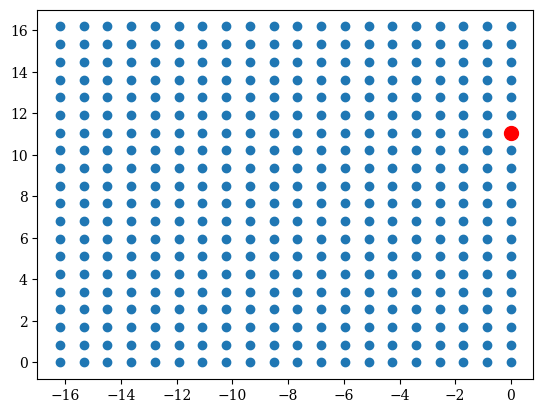

In [ ]:
plt.scatter(positions_rot[:, 0] * rad_to_arcsec, positions_rot[:, 1] * rad_to_arcsec)
plt.scatter(positions_rot[13, 0]*rad_to_arcsec, positions_rot[13, 1]*rad_to_arcsec, c='red', s=100, label='Closest Approach')

In [ ]:
phi_0/np.pi#+2*np.pi

-0.6616347913316158

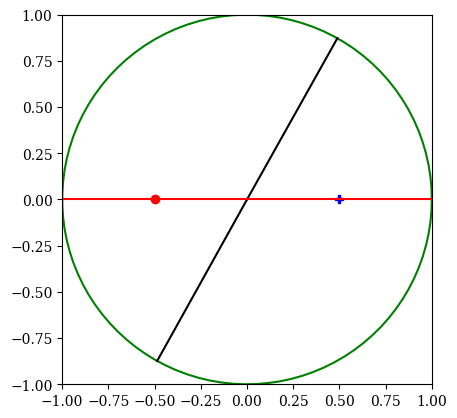

In [ ]:

r = 1
def deg2rad(deg):
    return deg * pi / 180
angles = np.linspace(0 * np.pi, 2 * np.pi, 100) 
xs = np.cos(angles)
ys = np.sin(angles)
plt.plot(xs, ys, color = 'green')

plt.plot(r-0.5, 0, marker = 'P', color = 'blue')
plt.plot(-r+0.5, 0, marker = 'o', color = 'red')
plt.plot([0, r * np.cos(phi_0)], [0, r * np.sin(phi_0)], color = "black")
plt.plot([0, r * np.cos(1.06)], [0, r * np.sin(1.06)], color = "black")

plt.plot([r, -r], [0, 0], color = 'red')
plt.xlim(-r, r)
plt.ylim(-r, r)
plt.gca().set_aspect('equal')

In [ ]:
np.arctan((((position_04[13,0] -4000)*theta_step* rad_to_arcsec)/((position_04[13,1] -4000)*theta_step* rad_to_arcsec)))

np.float64(1.0630056537797883)

In [ ]:
np.arctan(((position_04[13,1] -4000)*theta_step* rad_to_arcsec)/((position_04[13,0] -4000)*theta_step* rad_to_arcsec))

np.float64(0.5077906730151083)

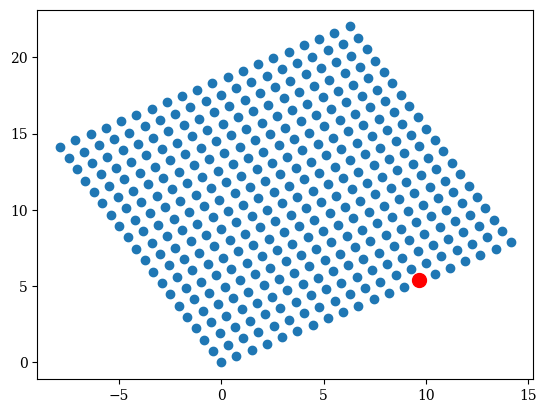

In [ ]:

plt.scatter((position_04[:,0] -4000)*theta_step* rad_to_arcsec, (position_04[:,1] -4000)*theta_step* rad_to_arcsec)
plt.scatter((position_04[13,0] -4000)*theta_step* rad_to_arcsec,
             (position_04[13,1] -4000)*theta_step* rad_to_arcsec, c='red', s=100, label='Closest Approach')

In [ ]:
0 0.03537143016689349
1 0.043472910153662885
2 0.05100339527065601
3 0.06463328997425065
4 0.07936342923504432
5 0.09428613054688025
12 0.0912142340076422
13 0.07118291263982032
14 0.06029496343841955
15 0.06254453174768425
16 0.07265872103507225
17 0.09003379199593148
20 0.06077278645195039
21 0.06568032704453768
22 0.07491597009484446
23 0.07923649258632041
24 0.09099422372084734

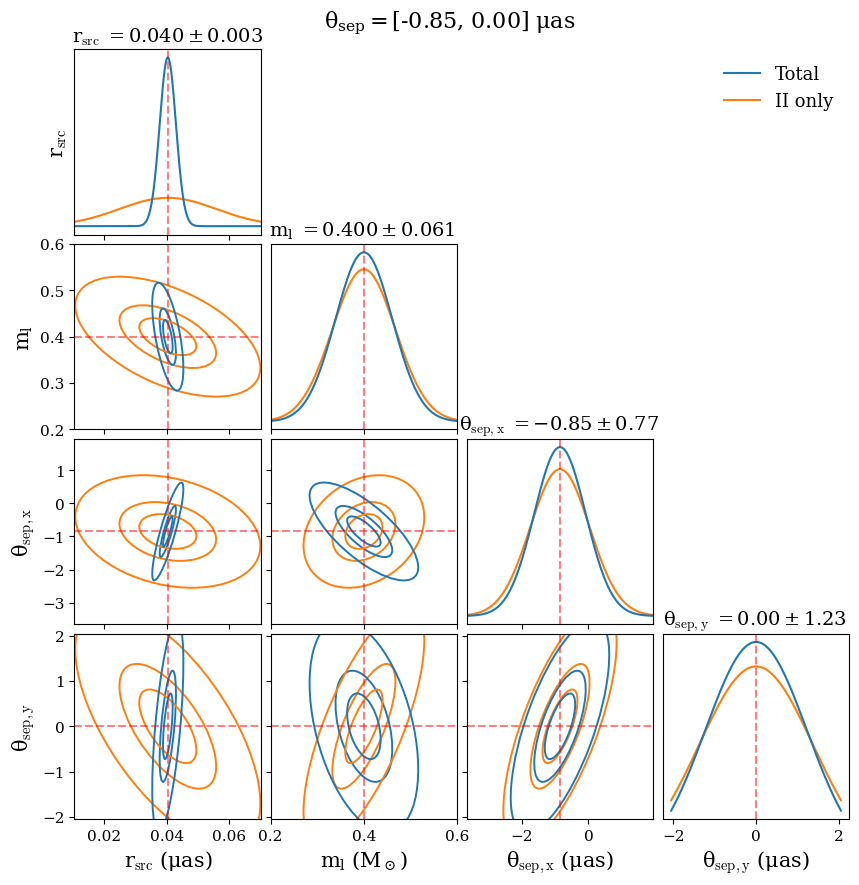

In [14]:
idx=20
pos_x_corner=(positions_rot[idx][0])
pos_y_corner=(positions_rot[idx][1])
mass_04_combo[idx]

titles = [r"$r_\text{src}\ (mas)$", r"$m_l\ (M_\odot)$",
          r"$\theta_{\rm sep,x}\ (mas)$", r"$\theta_{\rm sep,y}\ (mas)$"]

varlabels = [r"$r_\text{src}$", r"$m_l$", r"$\theta_{\rm sep,x}$", r"$\theta_{\rm sep,y}$"]
units = [r"$\mu as$", r"$M_\odot$", r"$\mu as$", r"$\mu as$"]
precision = [3, 3, 2, 2]

mean_vec = np.array([rad_mas, 0.4, pos_x_corner * rad_to_arcsec, pos_y_corner * rad_to_arcsec])
scales=[.03, .2, 2.8, 2.05] 
limits = np.array([[mean_vec[0]-scales[0], mean_vec[0]+scales[0]], [mean_vec[1]-scales[1], mean_vec[1]+scales[1]],
                   [mean_vec[2]-scales[2], mean_vec[2]+scales[2]], [mean_vec[3]-scales[3], mean_vec[3]+scales[3]]])

cov1 = cov_combo_04[idx] 
cov2 = cov_04[idx]

ndim = len(varlabels)

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(ndim, ndim, hspace=0.05, wspace=0.05)

axes = np.empty((ndim, ndim), dtype=object)
percentiles = [0.16, 0.84]
colors = ["C0", "C0", "C0"]  # or different colors/styles
linewidths = [0.8, 0.8]

colors2 = ["C1", "C1", "C1"]

for i in range(ndim):
    for j in range(ndim):

        if i < j:
            axes[i, j] = fig.add_subplot(gs[i, j])
            axes[i, j].axis("off")
            continue

        if i == j:
            axes[i, j] = fig.add_subplot(gs[i, j])
        else:
            axes[i, j] = fig.add_subplot( gs[i, j], sharex=axes[j, j],  sharey=axes[i, i] )

for i in range(ndim):
    for j in range(ndim):
        ax = axes[i,j]
        if i < j:
            continue

        if i == j:
            # 1D marginal
            sigma1 = np.sqrt(cov1[i,i])
            sigma2 = np.sqrt(cov2[i,i])
            x = np.linspace(limits[j][0], limits[j][1], 500)#mean_vec[i]-4*sigma1, mean_vec[i]+4*sigma1, 500)
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma2), color="C1")
            ax.plot(x, gaussian_1d(x, mean_vec[i], sigma1), color="C0")
            ax.set_yticks([])
            ax.tick_params(left=False)
            nd = precision[i]
            ax.set_title(fr"{varlabels[i]} $= {mean_vec[i]:.{nd}f} \pm {sigma1:.{nd}f}$ ",
                         fontsize=14)
            ax.axvline(mean_vec[[j,i]][1], color='r', linestyle='dashed', alpha=.5)
        else:
            # 2D ellipse
            mean_ij = mean_vec[[j,i]]
            cov1_ij = cov1[np.ix_([j,i],[j,i])]
            cov2_ij = cov2[np.ix_([j,i],[j,i])]
            ax.set_xlim(limits[j][0], limits[j][1])#mean_vec[j]-4*np.sqrt(cov1[j,j]),
                       # mean_vec[j]+4*np.sqrt(cov1[j,j]))
            ax.set_ylim(limits[i][0], limits[i][1])
                        #mean_vec[i]+4*np.sqrt(cov1[i,i]))
            ax.axvline(mean_ij[0], color='r', linestyle='dashed', alpha=.5)
            ax.axhline(mean_ij[1], color='r', linestyle='dashed', alpha=.5)
            plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=1, edgecolor="C1", linewidth=1.4)
            plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=1, edgecolor="C0", linewidth=1.4)

            for p, c, lw in zip(percentiles, colors2, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov2_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)
            for p, c, lw in zip(percentiles, colors, linewidths):
                n_sigma = np.sqrt(scipy.stats.chi2.ppf(p, df=2))  # df=2 for 2D
                plot_cov_ellipse(mean_ij, cov1_ij, ax, n_sigma=n_sigma,
                                 edgecolor=c, linewidth=1.4)

        ax.tick_params(labelsize=11)
            
for i in range(ndim):
    for j in range(ndim):
        ax = axes[i, j]
        if i != ndim - 1:
            ax.tick_params(labelbottom=False)
        if j != 0:
            ax.tick_params(labelleft=False)
        #if i!=j+1:
        ax.set_xlabel(f"{varlabels[j]} ({units[j]})", fontsize=15)
        if i>-1 and j==0:
            ax.set_ylabel(f"{varlabels[i]}", fontsize=15)
        
axes[0, -1].plot([], [], color="C0", label="Total")
axes[0, -1].plot([], [], color="C1", label="II only")
axes[0, -1].legend(frameon=False, fontsize=13)

title=r'$\theta_{{sep}} = [$' + str(format(pos_x_corner*rad_to_arcsec, '.2f')) + ', ' + str(format(pos_y_corner*rad_to_arcsec, '.2f')) + r'$]\ \mu$as'
fig.text( 0.5, 0.92, title, ha='center', va='top', fontsize=16)
#plt.text(-25, 1.45, r'$\theta_{{sep}} = [-0.31,  0.57]\ \mu$as', fontsize=18);
#plt.show()

plt.savefig('figures/corner04_ell.pdf', bbox_inches='tight')
#FileLink('figures/corner04_ell.pdf')

### Interpolate errors

In [15]:
n = int(np.sqrt(len(x_rot)))

x_grid = np.unique(positions_rot[:, 0].round(decimals=15))#*theta_step * image_size
x_grid = np.concat((x_grid, (-x_grid[len(x_grid)-2::-1])))
y_grid = np.unique(positions_rot[:, 1].round(decimals=15))#*theta_step * image_size
y_grid = np.concat((-y_grid[::-1], (y_grid[1:])))

rad_grid  = rad_04_combo.reshape(n, n)
mass_grid = mass_04_combo.reshape(n, n)
xpos_grid = posx_04_combo.reshape(n, n)
ypos_grid = posy_04_combo.reshape(n, n)


In [16]:
rad_grid  = one_quad_to_full(rad_04_combo, n)
mass_grid = one_quad_to_full(mass_04_combo, n)
xpos_grid = one_quad_to_full(posx_04_combo, n)
ypos_grid = one_quad_to_full(posy_04_combo, n)


In [17]:
# Build interpolators
rad_spline  = RegularGridInterpolator([x_grid, y_grid], rad_grid, method='linear')
mass_spline = RegularGridInterpolator([x_grid, y_grid], mass_grid, method='linear')
xpos_spline = RegularGridInterpolator([x_grid, y_grid], xpos_grid, method='linear') #takes position in radians, returns in mas
ypos_spline = RegularGridInterpolator([x_grid, y_grid], ypos_grid, method='linear')

In [18]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
#mass_interp = mass_spline.ev(X_fine.ravel(), Y_fine.ravel()).reshape(Y_fine.shape)

In [19]:
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
rad_interp = rad_spline(points).reshape(X_fine.shape)
mass_interp = mass_spline(points).reshape(X_fine.shape)
xpos_interp = xpos_spline(points).reshape(X_fine.shape)
ypos_interp = ypos_spline(points).reshape(X_fine.shape)

### Interpolate fisher matricies for m=0.8

In [20]:
f_combo_04=[]
for i in range(len(cov_combo_04)):
    f_combo_04.append(np.linalg.inv(cov_combo_04[i]))
f_combo_04=np.array(f_combo_04)
f_combo_04 = f_combo_04.reshape(n, n, 4, 4)
f_combo_04  = matrix_to_full(f_combo_04, n)

In [21]:
splines_f04 = [[RectBivariateSpline(x_grid, y_grid, f_combo_04[:, :, i, j])#, s=1e-24)
            for j in range(4)] for i in range(4)]
def fisher_spline(pos_arr):
    x=pos_arr[0]
    y=pos_arr[1]
    return np.array([[splines_f04[i][j](x, y)[0,0] for j in range(4)] for i in range(4)])

In [22]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 400)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 400)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')


In [23]:
Z_det=np.empty((len(fine_grid_x), len(fine_grid_y)))
for i, x in enumerate(fine_grid_x):
    for j, y in enumerate(fine_grid_y):
       
        f_original = fisher_spline([x, y])      
        Z_det[i, j] = np.linalg.det(f_original) 

In [24]:
interpolators = [[None for j in range(4)] for i in range(4)]

for i in range(4):
    for j in range(4):
        # Linear interpolation; 'bounds_error=False' allows extrapolation if needed
        interpolators[i][j] = RegularGridInterpolator(
            (x_grid, y_grid),
            f_combo_04[:, :, i, j], bounds_error=False, method='linear', fill_value=np.nan)
def fisher_interp_linear(pos):
    x, y = pos
    M = np.zeros((4, 4))
    for i in range(4):
        for j in range(4):
            M[i, j] = np.asarray(interpolators[i][j]([x, y])).ravel()[0]
    # enforce symmetry
    M = 0.5 * (M + M.T)
    return M
def fisher_interp_grid(pos):
    x, y = pos[:, 0], pos[:, 1]
    N = len(x)

    M = np.zeros((N, 4, 4))
    for i in range(4):
        for j in range(4):
            M[:, i, j] = interpolators[i][j](np.column_stack((x, y)))

    # enforce symmetry on the last two axes only
    M = 0.5 * (M + np.swapaxes(M, -1, -2))
    return M

In [25]:
fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)
Fvals_interp = fisher_interp_grid(points).reshape((200,200,4,4))


### Interpolate chi^2, centroids

In [26]:
chi_grid  = one_quad_to_full(chi_combo_04, n)

fine_grid_x=np.linspace(np.min(x_grid), np.max(x_grid), 200)
fine_grid_y=np.linspace(np.min(y_grid), np.max(y_grid), 200)
X_fine, Y_fine = np.meshgrid(fine_grid_x, fine_grid_y, indexing='ij')
points = np.stack([X_fine.ravel(), Y_fine.ravel()], axis=-1)

chi_spline  = RegularGridInterpolator([x_grid, y_grid], chi_grid, bounds_error=False, method='linear', fill_value=np.nan)
chi_interp  = chi_spline(points).reshape(X_fine.shape)

In [27]:

centroids=centroids.reshape(n,n,2,4)
Jcent_grid  = Jac_to_full(centroids, n)

interpolators_cent=[[None for i in range(4)] for a in range(2)]

for a in range(2):        # centroid x/y
    for i in range(4):    # parameters
        interpolators_cent[a][i] = RegularGridInterpolator(
        (x_grid, y_grid),
        Jcent_grid[:, :, a, i], bounds_error=False, method='linear', fill_value=np.nan)

def Jcent_interp(pos):
    x, y = pos
    J = np.zeros((2, 4))
    for a in range(2):
        for i in range(4):
            J[a, i] = np.asarray(interpolators_cent[a][i]([x, y])).ravel()[0]
    return J

cent_pres  = one_quad_to_full(cent_pres, n)
cent_spline = RegularGridInterpolator([x_grid, y_grid], cent_pres, method='linear', fill_value=np.nan)
cent_interp = cent_spline(points).reshape(X_fine.shape)

sigma_c1  = one_quad_to_full(sigma_c1, n)
sigma_c1_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1, method='linear', fill_value=np.nan)
sigma_c1_interp = sigma_c1_spline(points).reshape(X_fine.shape)

sigma_c2  = one_quad_to_full(sigma_c2, n)
sigma_c2_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2, method='linear', fill_value=np.nan)
sigma_c2_interp = sigma_c2_spline(points).reshape(X_fine.shape)


sigma_c1_res  = one_quad_to_full(sigma_c1_res, n)
sigma_c1res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c1_res, method='linear', fill_value=np.nan)
sigma_c1res_interp = sigma_c1res_spline(points).reshape(X_fine.shape)

sigma_c2_res  = one_quad_to_full(sigma_c2_res, n)
sigma_c2res_spline = RegularGridInterpolator([x_grid, y_grid], sigma_c2_res, method='linear', fill_value=np.nan)
sigma_c2res_interp = sigma_c2res_spline(points).reshape(X_fine.shape)


In [28]:
chi_grid_II  = one_quad_to_full(chis_04_II, n)
chi_spline_II  = RegularGridInterpolator([x_grid, y_grid], chi_grid_II, bounds_error=False, method='linear', fill_value=np.nan)

chi_grid_mag  = one_quad_to_full(chis_04_mag, n)
chi_spline_mag  = RegularGridInterpolator([x_grid, y_grid], chi_grid_mag, bounds_error=False, method='linear', fill_value=np.nan)

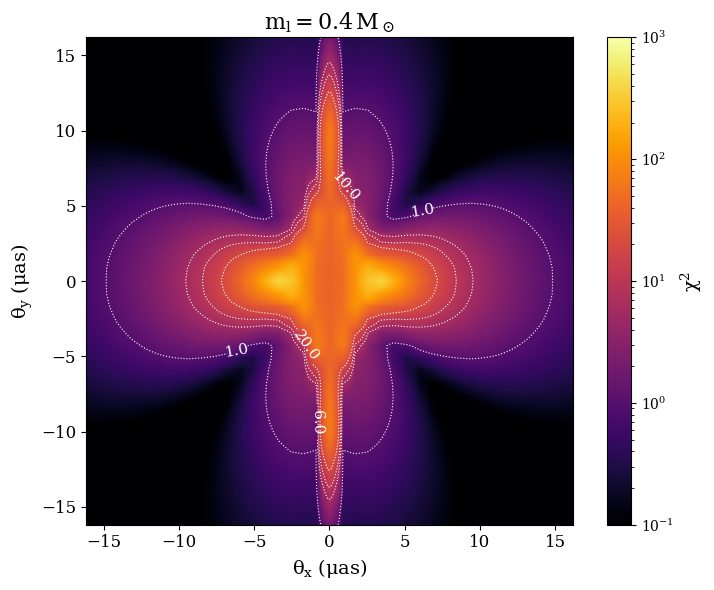

In [29]:
Z = np.flipud(chi_interp).T
X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

levels=[1, 6, 10, 20]
fig, ax = plt.subplots(figsize=(12, 6))

im = ax.imshow(Z, origin='lower', extent=extent, cmap='inferno', norm=matplotlib.colors.LogNorm(vmin=.1,vmax=1000),)
contours = ax.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax.clabel(contours, inline=True, fontsize=11, fmt="%.1f")

cbar = plt.colorbar(im, ax=ax, fraction=0.045, pad=.03)
cbar.set_label(r'$\chi^2$', fontsize=14)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('figures/chi04.pdf', bbox_inches='tight')


In [38]:
# Grid spacing (assumes a regular grid)
dx = X[0, 1] - X[0, 0]
dy = Y[1, 0] - Y[0, 0]

# Mask of detectable region
mask = Z > 6

# Total area where Z < 6
area = np.sum(mask) * dx * dy

# Equivalent circular radius
r_equiv = np.sqrt(area / np.pi)

print(f"Area-equivalent detectable radius = {r_equiv/rad_to_arcsec/theta_E_4} theta_E")

Area-equivalent detectable radius = [4.36037965] theta_E


In [39]:
area

np.float64(157.47282388197814)

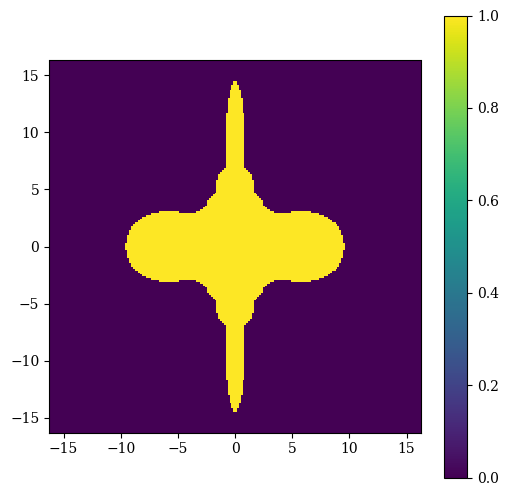

In [40]:
plt.figure(figsize=(6,6))
plt.pcolormesh(X, Y, mask, shading='nearest')
plt.gca().set_aspect('equal')
plt.colorbar()

In [36]:
print("Fraction of pixels:", mask.mean())

area = mask.sum() * dx * dy
print("Area =", area)
print("Equivalent radius =", np.sqrt(area/np.pi))

Fraction of pixels: 0.8513
Area = 901.523974248339
Equivalent radius = 16.940011618500957


### Error Plots

In [30]:
orig_map=plt.cm.get_cmap('cividis')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

bulk_vel=400
bulk_vel_err=100
vel_disp=178
vel_disp_err=35

# Apparent (image-fixed-frame) proper-motion scales for the map annotations
# (see get_velocities): the extremes lie along/perpendicular to the shear axis and
# are given by the eigenvalues of B = A^{-1} times the unlensed rate.
nu_unlensed = np.sqrt(bulk_vel**2+vel_disp**2)*1e5/((1+z_l)*D_l)*365.25*24*3600*rad_to_arcsec  # uas/yr
eigB = np.abs(np.linalg.eigvalsh(B_matrix))
mu_x = nu_unlensed*eigB.min()   # perpendicular to the shear axis (horizontal in plots)
mu_y = nu_unlensed*eigB.max()   # along the shear axis (vertical in plots)

/tmp/ipykernel_3494866/2471395885.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=plt.cm.get_cmap('cividis')


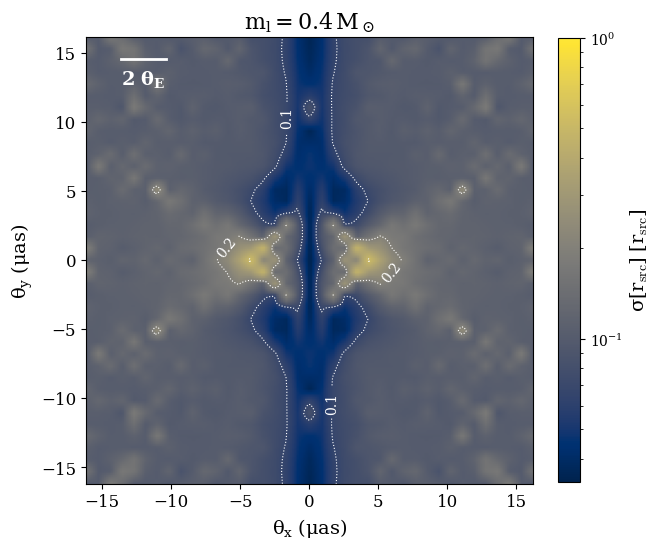

In [41]:
fig, (ax1) = plt.subplots(nrows=1, ncols=1, figsize=(6.6, 5.9))
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(rad_interp).T/rad_mas

levels=[1/15, 1/5, .5]
im=ax1.imshow(Z, origin='lower', cmap=orig_map, extent=extent,
              norm=matplotlib.colors.LogNorm(vmin=1/30, vmax=1))
cbar = plt.colorbar(im, ax=ax1, fraction=0.045)
cbar.set_label(r'$\sigma [r_\text{src}] \ [r_\text{src}]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale bar: 2 theta_E, same placement convention in all maps and masses
scale_length = float(np.ravel(2*theta_E_4*rad_to_arcsec)[0])  # scalar: text positions must not be arrays
x_start = np.min(fine_grid_x) - 4.2 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
plt.title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)
plt.tight_layout()

plt.savefig('figures/rad_04.pdf')


In [ ]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(mass_interp).T

levels=[.1, .2, .4, .8]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=5), extent=extent)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{m_l} \ [M_\odot]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

#scale bar: 2 theta_E, same placement convention in all maps and masses
scale_length = float(np.ravel(2*theta_E_4*rad_to_arcsec)[0])  # scalar: text positions must not be arrays
x_start = np.min(fine_grid_x) - 4.2 * scale_length
x_end = x_start + scale_length
y_pos = np.max(fine_grid_y*rad_to_arcsec)  + .1 *np.min(fine_grid_y*rad_to_arcsec)
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.text((x_start + x_end) / 2, y_pos * .85, r"$ 2 \ \theta_{E}$", color='white', ha='center', va='bottom', fontsize=14,
         fontweight='black')
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/mass_04.pdf')


In [ ]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.sqrt(np.flipud(xpos_interp).T**2+np.flipud(ypos_interp).T**2)

levels=[5, 10, 20]
im=ax1.imshow(Z, origin='lower',cmap=reversed_map,norm=matplotlib.colors.LogNorm(vmin=8e-1, vmax=1e2), extent=extent)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{\rm sep}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

# proper-motion annotation (apparent nu x 10 yr along / perpendicular to the shear
# axis), anchored top-left at a fixed fraction of the map extent so its placement is
# identical across the four lens masses (the arrow lengths are physical, i.e.
# mass-independent).
scale_length_x=mu_x*10
scale_length_y=mu_y*10
x_start = 0.85*extent[0]
x_end = x_start + scale_length_x
y_pos = 0.82*extent[3]
ax1.plot([x_start, x_end], [y_pos, y_pos], color='white', lw=2)
ax1.plot([x_start, x_start], [y_pos-scale_length_y, y_pos], color='white', lw=2)
ax1.text(x_start, y_pos * 1.05, r"$\vec{\nu} \ / $ 10 years", color='white', ha='left', va='bottom', fontsize=14,
         fontweight='black')

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/pos_04.pdf')


In [ ]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2_interp).T

levels=[.1, .3, 1, 3]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=3e1))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{c,2}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac2_04.pdf')


In [ ]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c2res_interp).T

levels=[.1, .3, .6]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=2e-2, vmax=2e0))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma^{\rm res}_{\theta_{c,2}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac2res_04.pdf')


In [ ]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1res_interp).T

levels=[.1, .3, .6]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=2e-2, vmax=2e0))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma^{\rm res}_{\theta_{c,1}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.2f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac1res_04.pdf')


In [ ]:
# Fixed panel geometry shared by all mass/pos/theta_c comparison maps (saved without
# a tight bbox), so every panel PDF has identical dimensions across quantities and
# lens masses; colorbar limits, contour levels, scale-bar placement, and fonts are
# shared across the four masses.
fig = plt.figure(figsize=(6.6, 5.9))
ax1 = fig.add_axes([0.115, 0.105, 0.72, 0.80])
cax = fig.add_axes([0.86, 0.105, 0.028, 0.80])
extent = np.array([np.min(fine_grid_x), np.max(fine_grid_x),  np.min(fine_grid_y), np.max(fine_grid_y)])*rad_to_arcsec

X, Y = np.meshgrid(fine_grid_x*rad_to_arcsec, fine_grid_y*rad_to_arcsec)
Z = np.flipud(sigma_c1_interp).T

levels=[.1, .3, 1, 3]
im=ax1.imshow(Z, origin='lower', cmap=reversed_map, extent=extent, norm=matplotlib.colors.LogNorm(vmin=5e-2, vmax=3e1))
cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r'$\sigma_{\theta_{c,1}} \ [\mu \rm as]$', fontsize=14)

#contours
contours = ax1.contour(X, Y, Z, levels=levels, colors='white', linewidths=0.8, linestyles='dotted')
ax1.clabel(contours, inline=True, fontsize=10, fmt="%.1f")

ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.tick_params(axis='both', which='minor', labelsize=10)
ax1.set_title(r'$m_l = 0.4 \, M_\odot$', fontsize=16)

ax1.set_xlabel(r'$\theta_x \ (\mu as)$', fontsize=14)
ax1.set_ylabel(r'$\theta_y \ (\mu as)$', fontsize=14)

plt.savefig('figures/thetac1_04.pdf')


### Uncertainties as a function of min impact parameter

In [67]:
def centroid_acceleration_uncertainty(centroid_cov_traj, times_days):
    """
    Estimate uncertainty on centroid acceleration by fitting a quadratic
    model c(t) = c0 + v*t + 0.5*a*t^2 to the centroid trajectory.

    Parameters
    ----------
    centroid_cov_traj : array, shape (N, 2, 2)
        Centroid position covariance at each timestep (radians^2)
    times_days : array, shape (N,)
        Observation times in days

    Returns
    -------
    cov_acc : array, shape (2, 2)
        Covariance of centroid acceleration [a_x, a_y] (rad/s^2)^2
    sigma_acc : array, shape (2,)
        1-sigma uncertainty on acceleration in each sky direction
    """
    times_s = times_days * 86400.0
    F = np.zeros((6, 6))

    for i, t in enumerate(times_s):
        # Design matrix: maps [cx0, cy0, vx, vy, ax, ay] -> [cx(t), cy(t)]
        A_i = np.array([[1, 0, t, 0, t**2/2, 0],
            [0, 1, 0, t, 0,t**2/2]])  # shape (2, 6)
        C_inv = np.linalg.inv(centroid_cov_traj[i])
        F += A_i.T @ C_inv @ A_i

    cov_full = np.linalg.inv(F)         # full (6,6) covariance
    cov_acc  = cov_full[4:6, 4:6]      # acceleration block only
    sigma_acc = np.sqrt(np.diag(cov_acc))
    return cov_acc, sigma_acc

def unlens_sigma_from_cov(cov_Theta, B_matrix, redshift, lens_dist_cm):
    """
    1-sigma uncertainties on the *physical* transverse velocity (vx, vy) in km/s
    from the 6x6 Theta covariance.  The fitted proper motion is the apparent,
    image-fixed-frame one (see get_velocities), so the conversion back to a physical
    velocity is v = (1 + z_l) D_l B^{-1} nu_tilde.
    """
    cov_mu = cov_Theta[4:6, 4:6]   # 2x2 apparent angular-velocity covariance

    B_inv = np.linalg.inv(B_matrix)
    J = (1 + redshift) * lens_dist_cm * B_inv   # Jacobian

    cov_v_cm = J @ cov_mu @ J.T                 # cm^2/s^2
    cov_v_kms = cov_v_cm / (1e5**2)             # (km/s)^2

    sigma_v_kms = np.sqrt(np.diag(cov_v_kms))
    return cov_v_cm, cov_v_kms, sigma_v_kms

def average_errors_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,chi_spline,dt_days=182.0,max_time_days=5*365.0,n_its=100,fisher_spline=fisher_interp_linear):

    fisher_thetas=[]
    cov_thetas=[]
    uncert_thetas=[]
    vels=[]
    chi_all=[]
    retries=[]
    Jcents=[]
    acc_covs=[]
    acc_sigmas=[]
    cent_cov_trajs=[]
    pos_trajs=[]
    time_trajs=[]

    for it in range(n_its):

        test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

        positions_traj=test_traj['positions_rad']
        times_traj=test_traj['times_days']

        retry=0

        fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
        chi_traj=np.array([chi_spline(p) for p in positions_traj])
        centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

        fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        while np.any(np.isnan(uncert_Theta)):

            retry+=1

            test_traj=sim_rand_traj(bulk_vel,bulk_vel_err,vel_disp,vel_disp_err,theta_max,N,redshift,lens_dist,B_matrix,dist,dt_days=dt_days,max_time_days=max_time_days)

            positions_traj=test_traj['positions_rad']
            times_traj=test_traj['times_days']

            fisher_alpha=np.array([fisher_spline(p) for p in positions_traj])
            chi_traj=np.array([chi_spline(p) for p in positions_traj])
            centJ_traj=np.array([Jcent_interp(p) for p in positions_traj]).reshape(-1,2,4)

            fisher_theta_traj=f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24))
            cov_Theta,uncert_Theta=parameter_uncertainties(fisher_theta_traj,theta_step,printout=False,numstars=1)

        retries.append(retry)

        pos_trajs.append(positions_traj)
        time_trajs.append(times_traj)
        vels.append(test_traj['velocity_kms'])

        chi_all.append(np.sum(chi_traj))

        C_alpha=np.linalg.inv(fisher_alpha)
        centroid_cov_traj=np.einsum('nij,njk,nlk->nil',centJ_traj,C_alpha,centJ_traj)

        cent_cov_trajs.append(centroid_cov_traj)

        acc_cov,sigma_acc=centroid_acceleration_uncertainty(centroid_cov_traj,times_traj)
        acc_covs.append(acc_cov)
        acc_sigmas.append(sigma_acc)

        Cinv_tot=np.sum(np.linalg.inv(centroid_cov_traj),axis=0)
        C_cent_tot=np.linalg.inv(Cinv_tot)
        Jcents.append(C_cent_tot)

        fisher_thetas.append(f_alpha_to_f_Theta(fisher_alpha,times_traj*(3600*24)))

        cov_v_cm,cov_v_kms,sigma_v_kms=unlens_sigma_from_cov(cov_Theta,B_matrix,redshift,lens_dist)

        cov_Theta,uncert_Theta=parameter_uncertainties(fisher_thetas[-1],theta_step,printout=False,numstars=1)

        uncert_unlensed=np.array(uncert_Theta.copy())
        uncert_unlensed[4]=sigma_v_kms[0]*4.848136811e-12
        uncert_unlensed[5]=sigma_v_kms[1]*4.848136811e-12

        uncert_thetas.append(uncert_unlensed)

    cov_thetas=np.array(cov_thetas)
    Jcents=np.array(Jcents)
    chi_all=np.array(chi_all)

    cov_avg=np.mean(cov_thetas,axis=0)

    uncert_thetas=np.array(uncert_thetas)
    uncert_avg=np.sum(uncert_thetas,axis=0)/n_its

    vels=np.array(vels)

    return cov_thetas,cov_avg,uncert_thetas,uncert_avg,vels,chi_all,retries,Jcents,acc_sigmas,cent_cov_trajs,pos_trajs,time_trajs,acc_covs


In [68]:
from II_funcs import *

In [ ]:
theta_E_8=np.sqrt(4*G*0.8*2e33/c**2*D_ls/(D_s*D_l))
theta_E_4=np.sqrt(4*G*0.4*2e33/c**2*D_ls/(D_s*D_l))
impact_params=np.linspace(0.3*theta_E_8,5.9*theta_E_8,40)[:38]

chi_tots,uncert_avgs,n_retries=[],[],[]
chi_dists,uncert_dists=[],[]
cent_all,acc_sigmas=[],[]
traj_cov_cent=[]
pos_traj,time_traj=[],[]
acc_covs_all = []   # new list

for impact_param in impact_params:
    
    out=average_errors_traj(bulk_vel, bulk_vel_err, vel_disp, vel_disp_err, np.max(x_grid), 8000, 
                            z_l, D_l, B_matrix, impact_param, chi_spline, fisher_spline=fisher_interp_linear, 
                            n_its=5000, dt_days=91.25, max_time_days=4*365.0)

    chi_tots.append(np.mean(out[5]))
    uncert_avgs.append(np.mean(out[2],axis=0))
    n_retries.append(out[6])

    chi_dists.append(out[5])
    uncert_dists.append(out[2])

    cent_all.append(out[9])
    acc_sigmas.append(out[8])
    traj_cov_cent.append(out[9])

    pos_traj.append(out[10])
    time_traj.append(out[11])
    acc_covs_all.append(out[12])

results = {
    "impact_params": impact_params,
    "chi_tots": np.array(chi_tots),
    "cent_all": np.array(cent_all),
    "uncert_avgs": np.array(uncert_avgs),
    "n_retried": np.array(n_retries),
    "chi_dists": np.array(chi_dists, dtype=object),
    "uncert_dists": np.array(uncert_dists, dtype=object),
    "acc_sigmas": np.array(acc_sigmas, dtype=object),
    "cent_traj": np.array(traj_cov_cent, dtype=object),
    "pos_traj": np.array(pos_traj, dtype=object),
    "time_traj": np.array(time_traj, dtype=object),
    "acc_covs": np.array(acc_covs_all, dtype=object),
    }

filename = "avgs_04_8yr_acc.npz"
try:
    existing = np.load(filename, allow_pickle=True)

    combined = {}

    old_nimpact = len(existing["impact_params"])
    new_nimpact = len(impact_params)

    for key, new_vals in results.items():
        old_vals = existing[key]

        if key == "impact_params":
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "uncert_avgs":
            combined[key] = np.vstack([old_vals, new_vals])

        elif key in ["chi_tots"]:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key in ["cent_all", "acc_sigmas", "cent_traj", "pos_traj", "time_traj", "chi_dists", "uncert_dists", 'acc_covs']:
            combined[key] = np.hstack([old_vals, new_vals])

        elif key == "n_retried":
            combined[key] = np.hstack([old_vals, new_vals])

        else:
            combined[key] = np.hstack([old_vals, new_vals])

except FileNotFoundError:
    combined = results

np.savez(filename, **combined)

/mnt/home/amoran/miniforge3/envs/GW_all/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/mnt/home/amoran/miniforge3/envs/GW_all/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [ ]:
# load it back in
data = np.load("avgs_04_8yr_acc.npz", allow_pickle=True)

impact_params_all = data["impact_params"]
chi_all= data["chi_tots"]
uncert_all = data["uncert_avgs"]
chi_dists_all = data["chi_dists"]
uncert_dists_all = data["uncert_dists"] 

uniq = np.unique(impact_params_all)
chi_mean   = np.zeros(len(uniq))
uncert_mean = np.zeros((len(uniq), uncert_all.shape[1]))

for i, u in enumerate(uniq):
    mask = impact_params_all == u
    chi_mean[i]   = chi_all[mask].mean()
    uncert_mean[i] = uncert_all[mask].mean(axis=0)

impact_params = uniq
chi_full=np.array(chi_dists_all)
uncert_full=np.array(uncert_dists_all)
chi_dists_all.shape

(38, 11000)

In [45]:
#check that all of these are in the area under chi^2=10, and they are!
n_retrys=data['n_retried']
cut=0
for i in range(len(n_retrys)):
    tries=np.sum(n_retrys[i])
    if tries>0:
        print("pos", np.array(impact_params/theta_E_4)[i], ':', tries)
    if np.percentile(chi_full, 50, axis=1)[i]<10 and cut==0:
        print('cutoff is ', np.array(impact_params/theta_E_4)[i])
        print('limit x axis to ', np.array(impact_params/theta_E_4)[i-1])
        xlim=np.array(impact_params/theta_E_4)[i-1]
        cut=10
        

# Fallback: if the median chi^2 never drops below the detection threshold (chi^2=10)
# anywhere in the simulated range, the microlensing model is preferred across the whole
# range, so plot out to the largest simulated |xi|.  (Previously xlim was left to stale
# kernel state from an earlier dataset; this makes a clean Run-All define it.)
if 'xlim' not in globals():
    xlim = float(np.max(impact_params/theta_E_4))
    print('median chi^2 >= 10 throughout; xlim set to full range =', xlim)


median chi^2 >= 10 throughout; xlim set to full range = 7.9377268923966815


In [ ]:
def apply_residual_cov_fast(cent_cov_traj, dtheta):
    I2 = np.eye(2)
    Cinv = np.linalg.inv(cent_cov_traj)
    prior = I2[None,None,None,:,:] / (dtheta[:,:,:,None,None]**2 + 1e-30)
    return np.linalg.inv(Cinv + prior)


def acceleration_sigma_from_cov_traj_fast(cent_cov_traj, times):
    n_imp, n_traj, n_t = times.shape
    t = times * 86400.0
    G = np.zeros((n_imp, n_traj, n_t, 2, 6))

    G[:,:,:,0,0] = 1
    G[:,:,:,0,2] = t
    G[:,:,:,0,4] = 0.5*t**2

    G[:,:,:,1,1] = 1
    G[:,:,:,1,3] = t
    G[:,:,:,1,5] = 0.5*t**2
    Cinv = np.linalg.inv(cent_cov_traj)
    GT = np.swapaxes(G, -1, -2)
    F = np.einsum('...ij,...jk,...kl->...il', GT, Cinv, G)
    F = np.sum(F, axis=2)
    cov = np.linalg.inv(F)
    return np.sqrt(np.diagonal(cov[:,:,4:6,4:6], axis1=-2, axis2=-1))
def acceleration_sigma_from_cov_traj_eig(cent_cov_traj, times):
    """
    Like acceleration_sigma_from_cov_traj_fast, but instead of returning the
    sqrt of the diagonal entries of the 2x2 acceleration covariance block
    (i.e. per-axis sigmas), this diagonalizes that 2x2 block and returns the
    sqrt of its eigenvalues, sorted ascending.

    Returns
    -------
    sigma_min, sigma_max : arrays of shape (n_imp, n_traj)
        sigma_min is sqrt(min eigenvalue) -- the tightest-constrained direction.
        sigma_max is sqrt(max eigenvalue) -- the loosest-constrained direction.
    """
    n_imp, n_traj, n_t = times.shape
    t = times * 86400.0
    G = np.zeros((n_imp, n_traj, n_t, 2, 6))

    G[:,:,:,0,0] = 1
    G[:,:,:,0,2] = t
    G[:,:,:,0,4] = 0.5*t**2

    G[:,:,:,1,1] = 1
    G[:,:,:,1,3] = t
    G[:,:,:,1,5] = 0.5*t**2

    Cinv = np.linalg.inv(cent_cov_traj)
    GT = np.swapaxes(G, -1, -2)
    F = np.einsum('...ij,...jk,...kl->...il', GT, Cinv, G)
    F = np.sum(F, axis=2)
    cov = np.linalg.inv(F)

    # 2x2 acceleration block: indices 4:6 correspond to (ax, ay)
    acc_block = cov[:, :, 4:6, 4:6]  # shape (n_imp, n_traj, 2, 2)

    # eigvalsh is for symmetric/Hermitian matrices and returns eigenvalues
    # in ascending order -- exactly what we want (min first, max second)
    eigvals = np.linalg.eigvalsh(acc_block)  # shape (n_imp, n_traj, 2)

    sigma_min = np.sqrt(eigvals[..., 0])
    sigma_max = np.sqrt(eigvals[..., 1])

    return sigma_min, sigma_max
def acc_sigma_min_max_from_covs(acc_covs):
    """
    acc_covs : array-like, shape (n_its, 2, 2) -- per-sample acceleration
        covariance matrices (rad/s^2)^2.

    Returns
    -------
    sigma_min, sigma_max : arrays, shape (n_its,)
        sqrt of the min/max eigenvalue of each 2x2 covariance matrix.
    """
    acc_covs = np.asarray(acc_covs, dtype=np.float64)
    eigvals = np.linalg.eigvalsh(acc_covs)   # shape (n_its, 2), ascending order
    sigma_min = np.sqrt(eigvals[..., 0])
    sigma_max = np.sqrt(eigvals[..., 1])
    return sigma_min, sigma_max

In [47]:
# |Delta theta_c| interpolant over the shear-frame grid (RADIANS), used to cap the
# per-epoch centroid covariance along trajectories (Eq. 24 of the paper).
dtheta_grid_rad = one_quad_to_full(np.linalg.norm(cent0_grid, axis=-1), n)
dtheta_spline = RegularGridInterpolator([x_grid, y_grid], dtheta_grid_rad,
                                        bounds_error=False, method='linear', fill_value=np.nan)

In [ ]:
acc_covs_data = data["acc_covs"]  # object array, one (n_its,2,2) block per impact param

sigma_min_list = []
sigma_max_list = []
for covs_i in acc_covs_data:
    smin, smax = acc_sigma_min_max_from_covs(covs_i)
    sigma_min_list.append(smin)
    sigma_max_list.append(smax)

# percentile + median across n_its for each impact parameter
acc_sigma_min_16 = np.array([np.nanpercentile(s, 16) for s in sigma_min_list])
acc_sigma_min_50 = np.array([np.nanpercentile(s, 50) for s in sigma_min_list])
acc_sigma_min_84 = np.array([np.nanpercentile(s, 84) for s in sigma_min_list])

(38, 11000, 2)

In [ ]:
acc_sigmas=data["acc_sigmas"]
acc_arr = np.array(acc_sigmas.tolist(), dtype=np.float64)
acc_sigma_mag = np.linalg.norm(acc_arr, axis=-1)
acc_sigma_mean = acc_sigma_mag  # name kept for downstream cells
acc_sigma_84 = np.nanpercentile(acc_sigma_mag, 84, axis=-1)
acc_sigma_16 = np.nanpercentile(acc_sigma_mag, 16, axis=-1)
acc_sigma_50 = np.nanpercentile(acc_sigma_mag, 50, axis=-1)

cent_traj = data["cent_traj"]
times = data["time_traj"]
pos_traj = data["pos_traj"] #rad

pos = np.array(pos_traj, dtype=np.float64)
dtheta_traj = dtheta_spline(pos)

cent_cov_res = apply_residual_cov_fast(np.array(cent_traj, dtype=np.float64), dtheta_traj)

acc_sigma_res = acceleration_sigma_from_cov_traj_fast(cent_cov_res, np.asarray(times, dtype=np.float64))
acc_sigma_min_res2, acc_sigma_max_res2 = acceleration_sigma_from_cov_traj_eig(cent_cov_res, np.asarray(times, dtype=np.float64))
acc_sigma_res2 = acc_sigma_min_res2  

In [63]:
acc_sigma_res2.shape

(38, 11000)

In [64]:
mag_acc_sig_r=np.linalg.norm(acc_sigma_res, axis=-1)
acc_sigma_res_50 = np.nanpercentile(mag_acc_sig_r, 50, axis=-1)

acc_sigma_res2_50 = np.nanpercentile(acc_sigma_res2, 50, axis=-1)


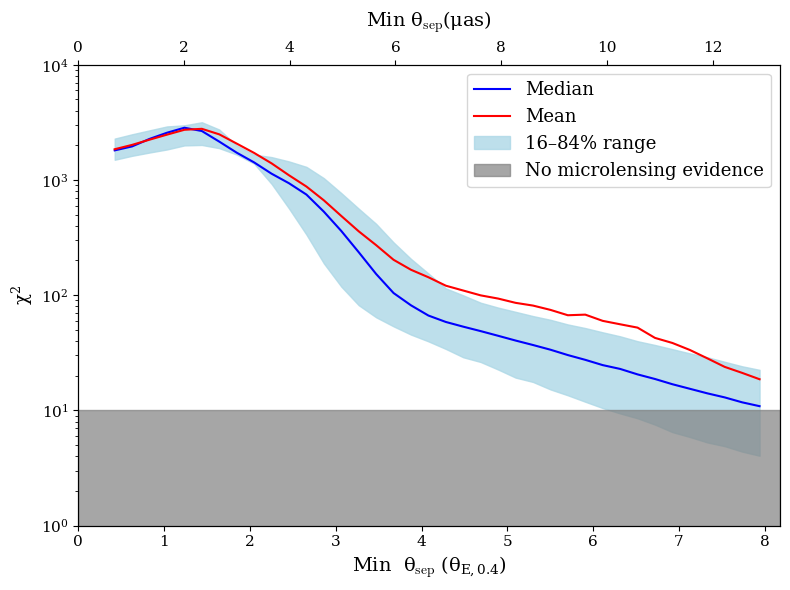

In [ ]:
p16= np.array(np.percentile(chi_full, 16, axis=1), dtype=float)
p84 = np.array(np.percentile(chi_full, 84, axis=1), dtype=float)
xlim_real=xlim*1.03
fig,ax = plt.subplots(figsize=(8,6))

ax.plot(impact_params / theta_E_4, np.percentile(chi_full, 50, axis=1), color='blue', label='Median')
ax.plot(impact_params / theta_E_4, chi_mean, label='Mean', color='red')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim_real*theta_E_4*rad_to_arcsec)


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.axhspan(0,10, label='No microlensing evidence', alpha=.7, color='gray')
ax.set_ylabel(r'$\chi^2$', fontsize=13)
ax.set_xlabel(r'Min  $\theta_{\text{sep}}$ ($\theta_{E, 0.4}$)', fontsize=14)
ax.set_yscale('log')
ax.set_xlim(0, xlim_real)
ax.set_ylim(1, 1e4)
ax.legend(fontsize=13)
fig.tight_layout() 
plt.savefig('figures/chi_traj_04.pdf')

#### Uncertainties 

In [55]:
# load in the averages
uncert_rads_avg =np.array(np.percentile(uncert_full[:,:,0], 50, axis=1))
uncert_mass_avg =np.array(np.percentile(uncert_full[:,:,1], 50, axis=1))
uncert_xpos_avg =np.array(np.percentile(uncert_full[:,:,2], 50, axis=1))
uncert_ypos_avg =np.array(np.percentile(uncert_full[:,:,3], 50, axis=1))
uncert_xvel_avg =np.array(np.percentile(uncert_full[:,:,4], 50, axis=1))
uncert_yvel_avg =np.array(np.percentile(uncert_full[:,:,5], 50, axis=1))
s_to_yr = 1 / (365.25 * 86400)  

In [56]:
import pandas as pd

In [57]:
# (stale scratch fragment, commented out so Run-All works)
# * rad_to_mas ***2

In [65]:
df=pd.DataFrame((np.array((impact_params/theta_E_8, uncert_rads_avg, uncert_mass_avg, 
                        uncert_xpos_avg, uncert_ypos_avg, uncert_xvel_avg, uncert_yvel_avg,
                        acc_sigma_50* rad_to_arcsec / s_to_yr**2, acc_sigma_res2_50*rad_to_arcsec / s_to_yr**2)).T),
                        columns=['impact_param', 'uncert_rad', 'uncert_mass', 'uncert_xpos', 'uncert_ypos', 'uncert_xvel', 'uncert_yvel', 
                                 'acc_sigma [mas/yr^2]', 'acc_sigma_res2 [mas/yr^2]'])

df

,impact_param,uncert_rad,uncert_mass,uncert_xpos,uncert_ypos,uncert_xvel,uncert_yvel,acc_sigma [mas/yr^2],acc_sigma_res2 [mas/yr^2]
0,0.3,0.00029,0.008015,0.060738,0.175189,173.294698,349.690845,0.030363,0.008591
1,0.44359,0.00029,0.008393,0.061311,0.166387,165.475663,339.170251,0.029452,0.008803
2,0.587179,0.000286,0.008692,0.063862,0.151783,152.31003,311.995945,0.029104,0.008928
3,0.730769,0.00028,0.009092,0.067513,0.135927,138.553946,279.388752,0.026926,0.008963
4,0.874359,0.000275,0.009568,0.070407,0.123594,125.132143,248.80093,0.024654,0.008887
5,1.017949,0.000274,0.009818,0.071131,0.108392,113.374053,219.15486,0.021843,0.008088
6,1.161538,0.00029,0.010379,0.073855,0.106341,107.000161,203.592435,0.02564,0.008358
7,1.305128,0.000311,0.01151,0.081244,0.114137,108.974788,201.708796,0.027766,0.009011
8,1.448718,0.00032,0.013566,0.093225,0.120004,113.886579,209.067112,0.02827,0.009242
9,1.592308,0.000315,0.01586,0.111017,0.126497,121.864561,228.01113,0.029143,0.008925


In [ ]:

s_to_yr = 1 / (365.25 * 86400)  
p16 = acc_sigma_16* rad_to_arcsec / s_to_yr**2
p84= acc_sigma_84* rad_to_arcsec / s_to_yr**2

fig,ax = plt.subplots(figsize=(8,6))
ylim=.3
ax.plot(impact_params / theta_E_4, acc_sigma_50*rad_to_arcsec/s_to_yr**2, color='blue', 
        label=r'$p_i= \Delta \theta_c$​ ')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.6, color='lightblue')


p16 = np.nanpercentile(mag_acc_sig_r, 16, axis=-1)* rad_to_arcsec / s_to_yr**2
p84=  np.nanpercentile(mag_acc_sig_r, 84, axis=-1)* rad_to_arcsec / s_to_yr**2
ax.plot(impact_params / theta_E_4, acc_sigma_res_50*rad_to_arcsec / s_to_yr**2, color='red',
    label=r'$p_i= \Delta \theta_c^\text{res}$​ ')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.5, color='pink')


#ticks_top=np.linspace(theta_E_4[0]*rad_to_arcsec, np.round(xlim)*theta_E_4[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_4*rad_to_arcsec)

#ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.4}$)', fontsize=14);
ax.set_ylabel(r"$\sigma [\frac{\partial^2 p_i}{\partial t^2}]$ ($\mu$as year$^{-2}$)",  fontsize=15)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

ax.legend(fontsize=12)
fig.tight_layout()

plt.savefig('figures/thetac_acc2_04.pdf')

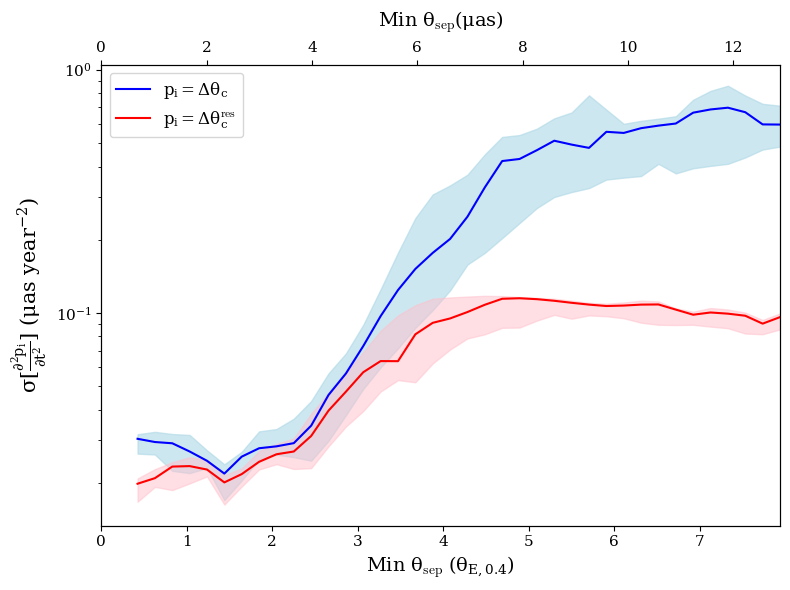

In [ ]:

s_to_yr = 1 / (365.25 * 86400)  
p16 = acc_sigma_16* rad_to_arcsec / s_to_yr**2
p84= acc_sigma_84* rad_to_arcsec / s_to_yr**2

fig,ax = plt.subplots(figsize=(8,6))
ylim=.3
ax.plot(impact_params / theta_E_4, acc_sigma_50*rad_to_arcsec/s_to_yr**2, color='blue', 
        label=r'$p_i= \Delta \theta_c$​ ')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.6, color='lightblue')


p16 = np.nanpercentile(mag_acc_sig_r, 16, axis=-1)* rad_to_arcsec / s_to_yr**2
p84=  np.nanpercentile(mag_acc_sig_r, 84, axis=-1)* rad_to_arcsec / s_to_yr**2
ax.plot(impact_params / theta_E_4, acc_sigma_res_50*rad_to_arcsec / s_to_yr**2, color='red',
    label=r'$p_i= \Delta \theta_c^\text{res}$​ ')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.5, color='pink')


#ticks_top=np.linspace(theta_E_4[0]*rad_to_arcsec, np.round(xlim)*theta_E_4[0]*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0, xlim*theta_E_4*rad_to_arcsec)

#ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.4}$)', fontsize=14);
ax.set_ylabel(r"$\sigma [\frac{\partial^2 p_i}{\partial t^2}]$ ($\mu$as year$^{-2}$)",  fontsize=15)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

ax.legend(fontsize=12)
fig.tight_layout()

plt.savefig('figures/thetac_acc_04.pdf')

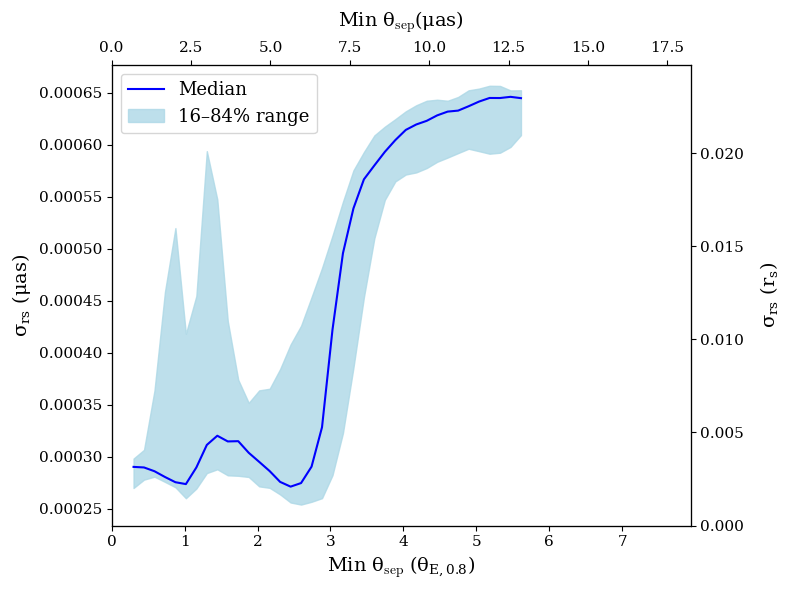

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,0], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,0], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ylim=.001
ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,0], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ticks_top=np.linspace(theta_E_8*rad_to_arcsec, 8*theta_E_8*rad_to_arcsec, 6) 

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)

ax_right = ax.twinx() # for top axis
ax_right.spines["top"].set_position(("axes", 1))
ax_right.set_ylabel(r'$\sigma_{rs}$ ($r_s$)',  fontsize=14, labelpad=10)
ax_right.set_ylim(0,ylim/rad_mas)

ax_right.tick_params(axis='both', which='major', labelsize=11)
ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14);
ax.set_ylabel(r"$\sigma_{rs}$ ($\mu$as)",  fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(.0004, ylim)

ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('figures/rad_traj_04.pdf')

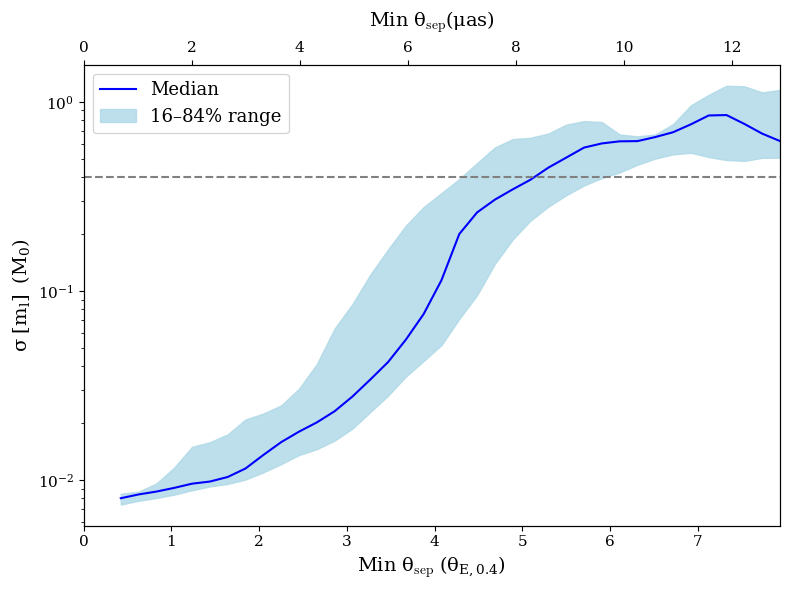

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,1], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,1], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6))
ax.plot(impact_params / theta_E_4, np.percentile(uncert_full[:,:,1], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_4*rad_to_arcsec)
ax.axhline(0.4, linestyle='dashed', color='gray')


ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.4}$)', fontsize=14)
ax.set_ylabel(r"$\sigma \ [m_l]\ \ (M_0)$", fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, .55)
ax.set_yscale('log')

ax.legend(fontsize=13)
fig.tight_layout()
plt.savefig('figures/mass_traj_04.pdf')

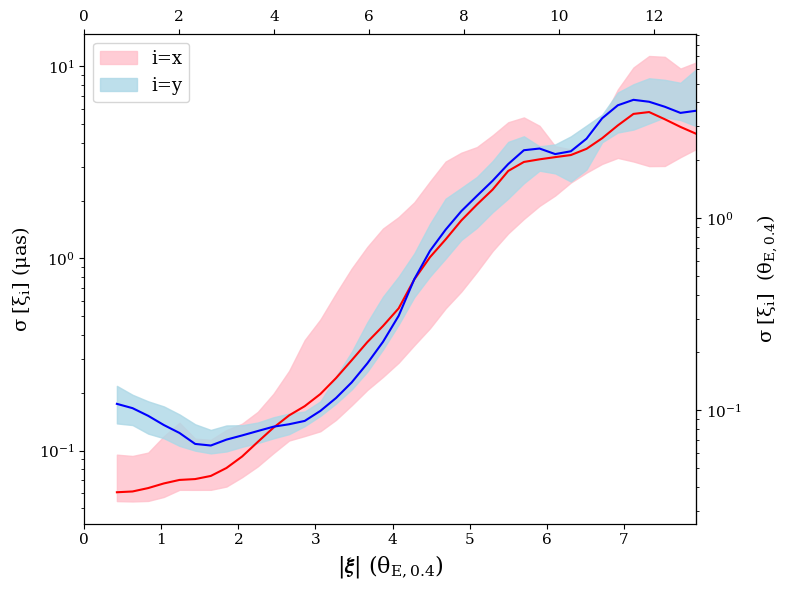

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,2], 16, axis=1), dtype=float)
p84= np.array(np.percentile(uncert_full[:,:,2], 84, axis=1), dtype=float)
fig,ax = plt.subplots(figsize=(8,6))

p16_y = np.array(np.percentile(uncert_full[:,:,3], 16, axis=1), dtype=float)
p84_y = np.array(np.percentile(uncert_full[:,:,3], 84, axis=1), dtype=float)

ax.plot(impact_params / theta_E_4, np.percentile(uncert_full[:,:,2], 50, axis=1), color='red')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='i=x', color='pink')

ax.plot(impact_params / theta_E_4, np.percentile(uncert_full[:,:,3], 50, axis=1), color='blue')
ax.fill_between(impact_params / theta_E_4, p16_y, p84_y,  alpha=0.8, label='i=y', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_4*rad_to_arcsec)

ylim=7

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma \ [\xi_i]$ ($\mu$as)", fontsize=14)
ax.legend()
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

# secondary y-axis in units of theta_{E,0.4}; secondary_yaxis tracks the log scale so ticks stay aligned
conv = float(np.ravel(rad_to_arcsec*theta_E_4)[0])  # muas per theta_{E,0.4}
ax_right = ax.secondary_yaxis('right', functions=(lambda v: v/conv, lambda v: v*conv))
ax_right.set_ylabel(r'$\sigma \ [\xi_i]$  ($\theta_{E, 0.4}$)', fontsize=14, labelpad=10)
ax_right.tick_params(axis='both', which='major', labelsize=11)

ax.legend(fontsize=13)
fig.tight_layout()


plt.savefig('figures/pos_traj_04.pdf')



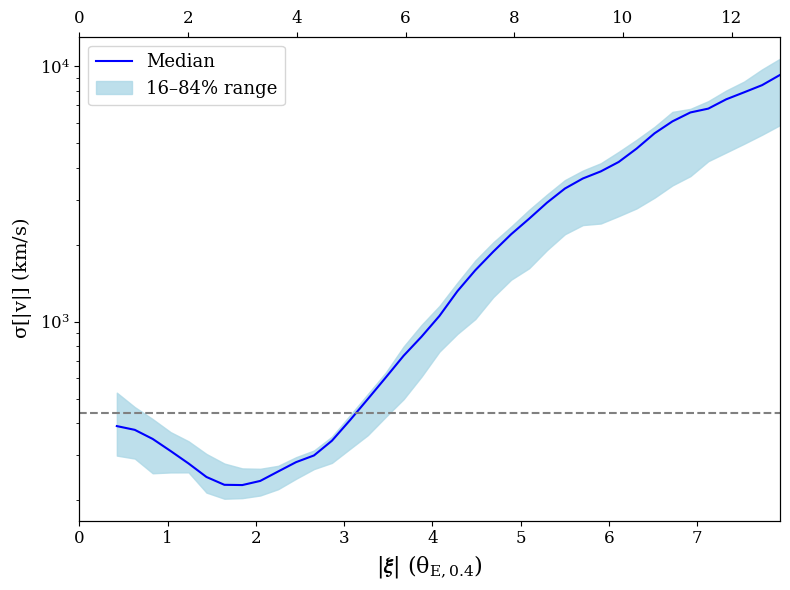

In [ ]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p16 = (np.array(np.percentile(vels, 16, axis=1), dtype=float))
p84 =  (np.array(np.percentile(vels, 84, axis=1), dtype=float))
p5 = (np.array(np.percentile(vels, 0, axis=1), dtype=float))
p95 =  (np.array(np.percentile(vels, 100, axis=1), dtype=float))

p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))
fig,ax = plt.subplots(figsize=(8,6))
ylim=7200


ax.plot(impact_params / theta_E_4, p50 , color='blue', label='Median')
ax.fill_between(impact_params / theta_E_4, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
#ax.fill_between(impact_params / theta_E_4, p5, p95,  alpha=0.2, label='Full range', color='grey')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
#ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_4*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=12)
ax.tick_params(axis='both', which='major', labelsize=12)

ax.set_xlabel(r'$|\boldsymbol{\xi}|$ ($\theta_{E, 0.4}$)', fontsize=16)
ax.set_ylabel(r"$\sigma [|v|]$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.set_yscale('log')

ax.legend(fontsize=13)
fig.tight_layout()

plt.savefig('figures/vel_traj_04.pdf')


In [ ]:
xvels=np.array(uncert_full[:,:,4])
yvels=np.array(uncert_full[:,:,5])
vels=np.array(xvels**2+yvels**2)**(.5)
p50=(np.array(np.percentile(vels, 50, axis=1), dtype=float))

vel_true=np.sqrt(bulk_vel**2+vel_disp**2)

In [ ]:
vel_true/(p50)*np.sqrt(5)

array([2.50948267, 2.59576772, 2.81719844, 3.140512  , 3.51362342,
       3.96801573, 4.25822209, 4.26763456, 4.11183806, 3.77645843,
       3.47208201, 3.26877526, 2.86350927, 2.38311224, 1.96819168,
       1.62124972, 1.33184444, 1.12176003, 0.9303874 , 0.74500216,
       0.61663692, 0.52192939, 0.44598031, 0.38796275, 0.33561968,
       0.29549203, 0.26994165, 0.25323978, 0.2326218 , 0.20621385,
       0.17972648, 0.1613648 , 0.1489338 , 0.14387456, 0.13229687,
       0.12421201, 0.11646931, 0.10623027])

In [ ]:
# (stale scratch fragment, commented out so Run-All works)
# xlim=

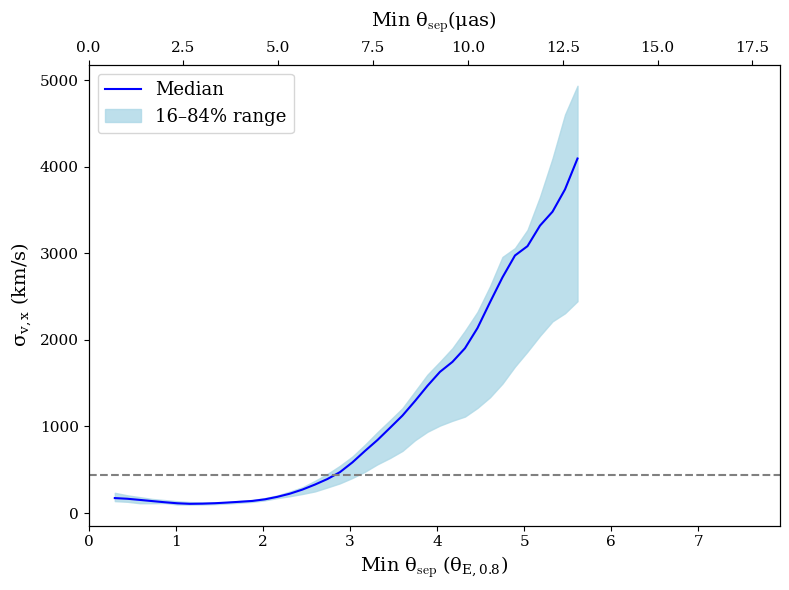

In [ ]:
p16 = np.array(np.percentile(uncert_full[:,:,4], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,4], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) #actual here has mean around 400 km/s and std 207.2 km/s
ylim=5.1

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,4], 50, axis=1),color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8*rad_to_arcsec)

ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, x}$ (km/s)", fontsize=14)
#plt.xlim(0.4, 2.5)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

IndexError: invalid index to scalar variable.

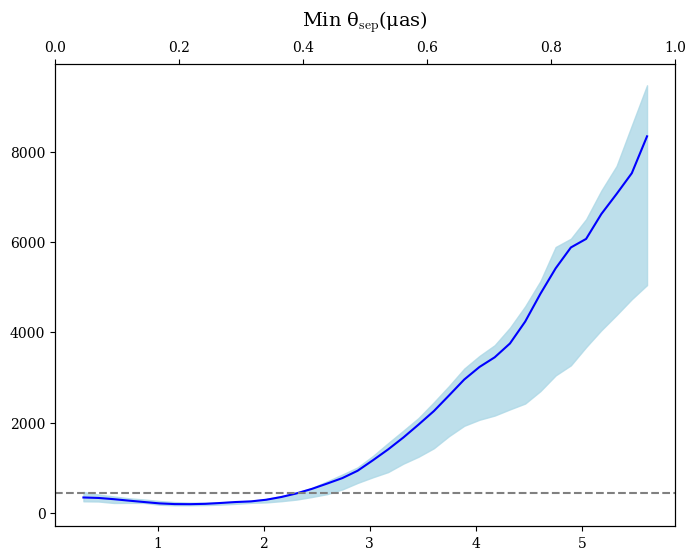

In [ ]:
# mean 0 and std 181.4 km/s
p16 = np.array(np.percentile(uncert_full[:,:,5], 16, axis=1), dtype=float)
p84 = np.array(np.percentile(uncert_full[:,:,5], 84, axis=1), dtype=float)

fig,ax = plt.subplots(figsize=(8,6)) 
ylim=3.7

ax.plot(impact_params / theta_E_8, np.percentile(uncert_full[:,:,5], 50, axis=1), color='blue', label='Median')
ax.fill_between(impact_params / theta_E_8, p16, p84,  alpha=0.8, label='16–84% range', color='lightblue')
ax.axhline(np.sqrt(bulk_vel**2+vel_disp**2), linestyle='dashed', color='gray')

ax_top = ax.twiny() # for top axis
ax_top.spines["top"].set_position(("axes", 1))
#ax_top.set_xticks(ticks_top, minor=False);
ax_top.set_xlabel(r'Min $\theta_{\text{sep}}$($\mu$as)',  fontsize=14, labelpad=10)
ax_top.set_xlim(0,xlim*theta_E_8[0]*rad_to_arcsec)

ax_top.tick_params(axis='both', which='major', labelsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)

ax.set_xlabel(r'Min $\theta_{\text{sep}}$ ($\theta_{E, 0.8}$)', fontsize=14)
ax.set_ylabel(r"$\sigma_{v, y}$ (km/s)", fontsize=14)
ax.set_xlim(0, xlim)
#ax.set_ylim(0, ylim)
ax.legend(fontsize=13)
fig.tight_layout()

In [ ]:
# 2/tau = 4 so we would expect a bit worse here 